In [ ]:
!pip install pillow pyyaml

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

# ================================================================
# HAZARD DETECTION - MASTER DATASET PREPROCESSING ANALYSIS
# GOOGLE COLAB + GOOGLE DRIVE
#
# Scans ONLY:
#   1. Prepared YOLO datasets
#   2. Prepared final_dataset folders
#   3. Converted coco_dataset
#
# Does NOT modify original files.
# ================================================================

from pathlib import Path
from collections import defaultdict, Counter
from PIL import Image
import yaml
import csv
import math
import os

# ================================================================
# 1. CONFIGURATION
# ================================================================

ROOT = Path("/content/drive/MyDrive/Hazard_Detection")

MASTER_CLASS_FILE = ROOT / "master_class" / "classes.yaml"

OUTPUT = ROOT / "preprocessing_analysis"

SPLITS = {"train", "val", "valid", "test"}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

EXCLUDED_PARTS = {
    "source_datasets",
    "bbox_report",
    ".complete",
    "__pycache__",
    "preprocessing_analysis"
}

OUTPUT.mkdir(parents=True, exist_ok=True)

assert ROOT.exists(), f"Repository not found: {ROOT}"
assert MASTER_CLASS_FILE.exists(), "Master classes.yaml not found!"

print("=" * 75)
print("HAZARD DETECTION MASTER PREPROCESSING")
print("=" * 75)


# ================================================================
# 2. LOAD MASTER CLASSES
# ================================================================

with open(MASTER_CLASS_FILE, "r", encoding="utf-8") as f:
    class_data = yaml.safe_load(f)

names = class_data["names"]

if isinstance(names, list):
    CLASSES = {i: name for i, name in enumerate(names)}
else:
    CLASSES = {int(k): v for k, v in names.items()}

print("\nMASTER CLASSES:", len(CLASSES))

for cid, name in sorted(CLASSES.items()):
    print(f"{cid:3} : {name}")


# ================================================================
# 3. DISCOVER APPROVED DATASET ROOTS
# ================================================================

def is_excluded(path):

    relative_parts = path.relative_to(ROOT).parts

    return any(
        part in EXCLUDED_PARTS or part.startswith(".")
        for part in relative_parts
    )


def discover_dataset_roots():

    roots = set()

    # Prepared YOLO and final_dataset directories
    for folder_name in ["YOLO", "final_dataset"]:

        for path in ROOT.rglob(folder_name):

            if not path.is_dir():
                continue

            if is_excluded(path):
                continue

            roots.add(path.resolve())

    # Special converted COCO dataset
    coco_root = ROOT / "coco_dataset"

    if coco_root.is_dir():
        roots.add(coco_root.resolve())

    return sorted(roots, key=lambda p: str(p))


# ================================================================
# 4. FIND TRAIN / VALIDATION / TEST PAIRS
# ================================================================

def get_child_case_insensitive(parent, name):

    if not parent.is_dir():
        return None

    for child in parent.iterdir():

        if child.is_dir() and child.name.lower() == name.lower():
            return child

    return None


def discover_splits(dataset_root):

    pairs = []
    seen = set()

    # Layout A:
    # YOLO/images/train
    # YOLO/labels/train

    image_root = dataset_root / "images"
    label_root = dataset_root / "labels"

    if image_root.is_dir() and label_root.is_dir():

        for split in sorted(SPLITS):

            img_dir = get_child_case_insensitive(image_root, split)
            lbl_dir = get_child_case_insensitive(label_root, split)

            if img_dir and lbl_dir:

                key = (str(img_dir.resolve()), str(lbl_dir.resolve()))

                if key not in seen:
                    pairs.append({
                        "split": split,
                        "images": img_dir,
                        "labels": lbl_dir
                    })
                    seen.add(key)

    # Layout B:
    # final_dataset/train/images
    # final_dataset/train/labels

    for split in sorted(SPLITS):

        split_root = get_child_case_insensitive(
            dataset_root, split
        )

        if split_root is None:
            continue

        img_dir = get_child_case_insensitive(split_root, "images")
        lbl_dir = get_child_case_insensitive(split_root, "labels")

        if img_dir and lbl_dir:

            key = (str(img_dir.resolve()), str(lbl_dir.resolve()))

            if key not in seen:
                pairs.append({
                    "split": split,
                    "images": img_dir,
                    "labels": lbl_dir
                })
                seen.add(key)

    return pairs


dataset_roots = discover_dataset_roots()

datasets = []

print("\n" + "=" * 75)
print("DATASET DISCOVERY REPORT")
print("=" * 75)

for root in dataset_roots:

    pairs = discover_splits(root)

    if not pairs:
        print("\nSKIPPED:", root.relative_to(ROOT))
        print("Reason: No matching image-label split structure")
        continue

    print("\nINCLUDED:", root.relative_to(ROOT))

    for pair in pairs:

        print("  SPLIT:", pair["split"].upper())

        datasets.append({
            "name": str(root.relative_to(ROOT)),
            "split": pair["split"],
            "images": pair["images"],
            "labels": pair["labels"]
        })

print("\nTOTAL APPROVED DATASET-SPLIT PAIRS:", len(datasets))

assert datasets, "No prepared datasets were discovered!"


# ================================================================
# 5. INITIALIZE ANALYSIS STORAGE
# ================================================================

class_stats = defaultdict(Counter)
bbox_stats = defaultdict(list)
dataset_stats = defaultdict(Counter)

issues = []

total_images = 0
total_instances = 0
total_valid_boxes = 0
total_invalid_boxes = 0


# ================================================================
# 6. PROCESS ALL DATASETS
# ================================================================

for dataset in datasets:

    name = dataset["name"]
    split = dataset["split"]

    key = (name, split)

    image_dir = dataset["images"]
    label_dir = dataset["labels"]

    print("\n" + "=" * 75)
    print("PROCESSING:", name)
    print("SPLIT:", split.upper())
    print("=" * 75)

    # Get images
    image_map = {
        p.stem: p
        for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    }

    label_files = sorted(label_dir.glob("*.txt"))

    stats = dataset_stats[key]

    stats["images"] = len(image_map)
    stats["label_files"] = len(label_files)

    total_images += len(image_map)

    matched_stems = set()
    nonempty_stems = set()

    for label_file in label_files:

        stem = label_file.stem
        image_path = image_map.get(stem)

        # --------------------------------------------------------
        # MISSING IMAGE
        # --------------------------------------------------------

        if image_path is None:

            stats["labels_without_image"] += 1

            issues.append([
                name, split, str(label_file),
                "Missing corresponding image"
            ])

            continue

        matched_stems.add(stem)

        # --------------------------------------------------------
        # READ IMAGE DIMENSIONS
        # --------------------------------------------------------

        try:

            with Image.open(image_path) as img:
                image_width, image_height = img.size

            if image_width <= 0 or image_height <= 0:
                raise ValueError("Invalid image dimensions")

        except Exception as e:

            issues.append([
                name, split, str(image_path),
                f"Image read error: {e}"
            ])

            continue

        # --------------------------------------------------------
        # READ ANNOTATIONS
        # --------------------------------------------------------

        with open(label_file, "r", encoding="utf-8") as f:
            lines = f.readlines()

        nonempty_lines = [
            line for line in lines if line.strip()
        ]

        if not nonempty_lines:

            stats["empty_label_files"] += 1
            continue

        nonempty_stems.add(stem)

        stats["nonempty_label_images"] += 1

        instance_count = 0
        valid_count = 0
        invalid_count = 0

        present_classes = set()

        for line_number, line in enumerate(lines, 1):

            if not line.strip():
                continue

            values = line.split()

            # ----------------------------------------------------
            # ANNOTATION FORMAT CHECK
            # ----------------------------------------------------

            if len(values) != 5:

                issues.append([
                    name, split, str(label_file),
                    f"Invalid YOLO format at line {line_number}"
                ])

                stats["malformed_lines"] += 1
                continue

            try:

                raw_class_id = float(values[0])
                class_id = int(raw_class_id)

                if raw_class_id != class_id:
                    raise ValueError("Class ID must be an integer")

                xc, yc, bw, bh = map(float, values[1:])

                if not all(
                    math.isfinite(v)
                    for v in [xc, yc, bw, bh]
                ):
                    raise ValueError("Non-finite coordinate")

            except (ValueError, OverflowError) as e:

                issues.append([
                    name, split, str(label_file),
                    f"Invalid annotation at line {line_number}: {e}"
                ])

                stats["malformed_lines"] += 1
                continue

            # ----------------------------------------------------
            # CLASS MAPPING
            # ----------------------------------------------------

            class_name = CLASSES.get(
                class_id,
                f"UNKNOWN_{class_id}"
            )

            if class_id not in CLASSES:

                issues.append([
                    name, split, str(label_file),
                    f"Unknown master class ID: {class_id}"
                ])

                stats["unknown_class_instances"] += 1

            # ----------------------------------------------------
            # COUNT INSTANCES
            # ----------------------------------------------------

            class_stats[key][class_id] += 1

            instance_count += 1
            total_instances += 1

            present_classes.add(class_id)

            # ----------------------------------------------------
            # VALIDATE BOUNDING BOX
            # ----------------------------------------------------

            valid = True

            if bw <= 0 or bh <= 0:
                valid = False

            if not (0 <= xc <= 1 and 0 <= yc <= 1):
                valid = False

            if xc - bw / 2 < -1e-6 or xc + bw / 2 > 1 + 1e-6:
                valid = False

            if yc - bh / 2 < -1e-6 or yc + bh / 2 > 1 + 1e-6:
                valid = False

            if not valid:

                invalid_count += 1
                total_invalid_boxes += 1

                issues.append([
                    name, split, str(label_file),
                    f"Invalid/out-of-bounds bbox at line {line_number}"
                ])

                continue

            # ----------------------------------------------------
            # BOUNDING BOX DIMENSIONS
            # ----------------------------------------------------

            valid_count += 1
            total_valid_boxes += 1

            pixel_width = bw * image_width
            pixel_height = bh * image_height

            pixel_area = pixel_width * pixel_height

            aspect_ratio = (
                pixel_width / pixel_height
                if pixel_height > 0 else float("nan")
            )

            bbox_stats[(name, split, class_id)].append({

                "norm_width": bw,
                "norm_height": bh,
                "norm_area": bw * bh,

                "pixel_width": pixel_width,
                "pixel_height": pixel_height,
                "pixel_area": pixel_area,

                "aspect_ratio": aspect_ratio
            })

        # --------------------------------------------------------
        # IMAGE-LEVEL STATISTICS
        # --------------------------------------------------------

        stats["annotation_rows"] += instance_count
        stats["valid_boxes"] += valid_count
        stats["invalid_boxes"] += invalid_count

        for cid in present_classes:
            stats[f"images_class_{cid}"] += 1

    # ------------------------------------------------------------
    # FINAL DATASET STATISTICS
    # ------------------------------------------------------------

    stats["matched_label_files"] = len(matched_stems)

    stats["images_without_label_file"] = (
        len(image_map) - len(matched_stems)
    )

    stats["images_without_valid_annotation_file"] = (
        len(image_map) - len(nonempty_stems)
    )

    print("Images:", stats["images"])
    print("Label files:", stats["label_files"])
    print("Nonempty annotation images:", stats["nonempty_label_images"])
    print("Instances:", stats["annotation_rows"])
    print("Valid boxes:", stats["valid_boxes"])
    print("Invalid boxes:", stats["invalid_boxes"])


# ================================================================
# 7. INSTANCE DISTRIBUTION REPORT
# ================================================================

with open(
    OUTPUT / "instance_distribution.csv",
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "dataset",
        "split",
        "class_id",
        "class_name",
        "instances",
        "images_containing_class"
    ])

    for (name, split), stats in sorted(dataset_stats.items()):

        counts = class_stats[(name, split)]

        all_ids = sorted(set(CLASSES) | set(counts))

        for cid in all_ids:

            writer.writerow([
                name,
                split,
                cid,
                CLASSES.get(cid, f"UNKNOWN_{cid}"),
                counts[cid],
                stats[f"images_class_{cid}"]
            ])


# ================================================================
# 8. BOUNDING BOX STATISTICS REPORT
# ================================================================

with open(
    OUTPUT / "bounding_box_statistics.csv",
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "dataset",
        "split",
        "class_id",
        "class_name",
        "valid_instances",

        "avg_norm_width",
        "avg_norm_height",
        "min_norm_width",
        "max_norm_width",
        "min_norm_height",
        "max_norm_height",

        "avg_norm_area",
        "median_norm_area",

        "avg_pixel_width",
        "avg_pixel_height",
        "avg_pixel_area",

        "avg_aspect_ratio",
        "median_aspect_ratio"
    ])

    for (name, split, cid), boxes in sorted(bbox_stats.items()):

        def vals(field):
            return [b[field] for b in boxes]

        ratios = [
            b["aspect_ratio"]
            for b in boxes
            if math.isfinite(b["aspect_ratio"])
        ]

        writer.writerow([
            name,
            split,
            cid,
            CLASSES.get(cid, f"UNKNOWN_{cid}"),
            len(boxes),

            mean(vals("norm_width")),
            mean(vals("norm_height")),

            min(vals("norm_width")),
            max(vals("norm_width")),

            min(vals("norm_height")),
            max(vals("norm_height")),

            mean(vals("norm_area")),
            median(vals("norm_area")),

            mean(vals("pixel_width")),
            mean(vals("pixel_height")),
            mean(vals("pixel_area")),

            mean(ratios) if ratios else "",
            median(ratios) if ratios else ""
        ])


# ================================================================
# 9. DATASET SUMMARY REPORT
# ================================================================

with open(
    OUTPUT / "dataset_summary.csv",
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "dataset",
        "split",
        "images",
        "label_files",
        "matched_label_files",
        "nonempty_label_images",
        "empty_label_files",
        "images_without_label_file",
        "images_without_valid_annotation_file",
        "labels_without_image",
        "annotation_rows",
        "valid_boxes",
        "invalid_boxes",
        "malformed_lines",
        "unknown_class_instances"
    ])

    for (name, split), s in sorted(dataset_stats.items()):

        writer.writerow([
            name,
            split,
            s["images"],
            s["label_files"],
            s["matched_label_files"],
            s["nonempty_label_images"],
            s["empty_label_files"],
            s["images_without_label_file"],
            s["images_without_valid_annotation_file"],
            s["labels_without_image"],
            s["annotation_rows"],
            s["valid_boxes"],
            s["invalid_boxes"],
            s["malformed_lines"],
            s["unknown_class_instances"]
        ])


# ================================================================
# 10. DATA QUALITY ISSUES REPORT
# ================================================================

with open(
    OUTPUT / "data_quality_issues.csv",
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "dataset",
        "split",
        "file",
        "issue"
    ])

    writer.writerows(issues)


# ================================================================
# 11. OVERALL MASTER CLASS DISTRIBUTION
# ================================================================

overall = Counter()
overall_by_split = defaultdict(Counter)

for (name, split), counts in class_stats.items():

    overall.update(counts)
    overall_by_split[split].update(counts)


with open(
    OUTPUT / "master_class_totals.csv",
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "class_id",
        "class_name",
        "train_instances",
        "validation_instances",
        "test_instances",
        "total_instances"
    ])

    for cid in sorted(set(CLASSES) | set(overall)):

        writer.writerow([
            cid,
            CLASSES.get(cid, f"UNKNOWN_{cid}"),

            overall_by_split["train"][cid],

            overall_by_split["val"][cid]
            + overall_by_split["valid"][cid],

            overall_by_split["test"][cid],

            overall[cid]
        ])


# ================================================================
# 12. FINAL TERMINAL SUMMARY
# ================================================================

print("\n\n")
print("=" * 85)
print("HAZARD DETECTION - FINAL PREPROCESSING ANALYSIS")
print("=" * 85)

print("Dataset-split pairs:", len(datasets))
print("Total images:", f"{total_images:,}")
print("Total annotation instances:", f"{total_instances:,}")
print("Valid bounding boxes:", f"{total_valid_boxes:,}")
print("Invalid bounding boxes:", f"{total_invalid_boxes:,}")
print("Data quality issues:", f"{len(issues):,}")

print("\n" + "=" * 85)
print("MASTER CLASS INSTANCE DISTRIBUTION")
print("=" * 85)

print(
    f"{'ID':<8}"
    f"{'CLASS':<30}"
    f"{'TRAIN':>12}"
    f"{'VALIDATION':>14}"
    f"{'TEST':>12}"
    f"{'TOTAL':>12}"
)

for cid in sorted(set(CLASSES) | set(overall)):

    train = overall_by_split["train"][cid]

    validation = (
        overall_by_split["val"][cid]
        + overall_by_split["valid"][cid]
    )

    test = overall_by_split["test"][cid]

    print(
        f"{cid:<8}"
        f"{CLASSES.get(cid, f'UNKNOWN_{cid}'):<30}"
        f"{train:>12,}"
        f"{validation:>14,}"
        f"{test:>12,}"
        f"{overall[cid]:>12,}"
    )


# ================================================================
# 13. REPORT FILES
# ================================================================

print("\n" + "=" * 85)
print("GENERATED REPORTS")
print("=" * 85)

for report in sorted(OUTPUT.glob("*.csv")):

    print(
        f"{report.name:<40}"
        f"{report.stat().st_size / 1024:>10.2f} KB"
    )

print("\nREPORT LOCATION:")
print(OUTPUT)

print("\n" + "=" * 85)
print("MASTER PREPROCESSING ANALYSIS COMPLETE!")
print("=" * 85)


HAZARD DETECTION MASTER PREPROCESSING

MASTER CLASSES: 21
  0 : person
  1 : two_wheeler
  2 : car
  3 : auto_rickshaw
  4 : large_vehicle
  5 : large_animal
  6 : dog
  7 : pothole
  8 : open_drain
  9 : speed_breaker
 10 : stairs_up
 11 : stairs_down
 12 : curb_or_step
 13 : obstacle
 14 : vendor_stall
 15 : bench
 16 : chair
 17 : door
 18 : sports_balls
 19 : traffic_lights
 20 : other_hazards

DATASET DISCOVERY REPORT

INCLUDED: raw_datasets/auto/YOLO
  SPLIT: TEST
  SPLIT: TRAIN
  SPLIT: VAL

INCLUDED: raw_datasets/doors/final_dataset
  SPLIT: TEST
  SPLIT: TRAIN
  SPLIT: VALID

INCLUDED: raw_datasets/indian_vehicles/YOLO
  SPLIT: TEST
  SPLIT: TRAIN
  SPLIT: VALID

INCLUDED: raw_datasets/obstacle/final_dataset
  SPLIT: TEST
  SPLIT: TRAIN
  SPLIT: VALID

INCLUDED: raw_datasets/potholes_kaggle/YOLO
  SPLIT: TEST
  SPLIT: TRAIN
  SPLIT: VAL

INCLUDED: raw_datasets/stairs/kaggle_1/final stairs/YOLO
  SPLIT: TEST
  SPLIT: TRAIN
  SPLIT: VALID

TOTAL APPROVED DATASET-SPLIT PAIRS: 18


In [ ]:

# ============================================================
# COMPLETE YOLO DATASET PREPROCESSING ANALYSIS
# Google Colab + Google Drive
# ============================================================
#
# ANALYSES:
# 1. Dataset and split discovery
# 2. Images and annotation files
# 3. Instances per class
# 4. Bounding-box statistics
# 5. Annotation quality checks
# 6. Missing images / labels and empty labels
# 7. Unknown class IDs
# 8. Dataset-level and split-level summaries
# 9. CSV report generation
#
# IMPORTANT:
# All annotations must already use your MASTER CLASS MAPPING.
# This script analyses class IDs; it does NOT remap them.
#
# ============================================================


# =========================
# 1. IMPORTS
# =========================

import os
import math
import statistics
from pathlib import Path
from collections import defaultdict, Counter

import pandas as pd
import yaml


# =========================
# 2. CONFIGURATION
# =========================

# Your Google Drive project folder
ROOT = Path("/content/drive/MyDrive/Hazard_Detection")

# Master class YAML file
MASTER_CLASSES_FILE = ROOT / "master_class" / "classes.yaml"

# Where all CSV reports will be saved
REPORT_DIR = ROOT / "preprocessing_analysis_reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Explicit dataset paths
DATASET_PATHS = [
    "raw_datasets/potholes_kaggle/YOLO",
    "raw_datasets/coco_dataset",
    "raw_datasets/indian_vehicles/YOLO",
    "raw_datasets/auto/YOLO",
    "raw_datasets/stairs/kaggle_1/final stairs/YOLO",
    "raw_datasets/speed_breaker",
    "raw_datasets/curb_or_step",
    "raw_datasets/obstacle/final_dataset",
    "raw_datasets/doors/final_dataset",
]

SPLIT_NAMES = ["train", "val", "valid", "test"]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"
}

# Set to True to print every individual dataset's detailed results
PRINT_DETAILED_RESULTS = True


# =========================
# 3. CHECK PROJECT ROOT
# =========================

print("=" * 80)
print("YOLO DATASET PREPROCESSING ANALYSIS")
print("=" * 80)

if not ROOT.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {ROOT}\n"
        "Check that Google Drive is mounted and ROOT is correct."
    )

print("Project root:", ROOT)
print("Report folder:", REPORT_DIR)


# =========================
# 4. LOAD MASTER CLASSES
# =========================

if MASTER_CLASSES_FILE.is_file():

    with open(MASTER_CLASSES_FILE, "r") as f:
        master_data = yaml.safe_load(f)

    names = master_data.get("names", {})

    if isinstance(names, dict):
        MASTER_CLASSES = {
            int(class_id): str(class_name)
            for class_id, class_name in names.items()
        }

    elif isinstance(names, list):
        MASTER_CLASSES = {
            class_id: str(class_name)
            for class_id, class_name in enumerate(names)
        }

    else:
        MASTER_CLASSES = {}

    print("\nMaster class file loaded:")
    print(MASTER_CLASSES_FILE)
    print("Number of master classes:", len(MASTER_CLASSES))

else:
    MASTER_CLASSES = {}

    print("\nWARNING: Master classes YAML not found.")
    print("Class names will be displayed as class_ID.")
    print("Expected location:", MASTER_CLASSES_FILE)


def get_class_name(class_id):

    return MASTER_CLASSES.get(
        class_id,
        f"class_{class_id}"
    )


# =========================
# 5. DATASET DISCOVERY
# =========================

def discover_splits(dataset_root):

    pairs = []
    seen = set()

    # Layout A:
    # images/train
    # labels/train

    image_root = dataset_root / "images"
    label_root = dataset_root / "labels"

    if image_root.is_dir() and label_root.is_dir():

        for split in SPLIT_NAMES:

            img_dir = image_root / split
            lbl_dir = label_root / split

            if img_dir.is_dir() and lbl_dir.is_dir():

                key = (
                    str(img_dir.resolve()),
                    str(lbl_dir.resolve())
                )

                if key not in seen:

                    pairs.append({
                        "split": split,
                        "images": img_dir,
                        "labels": lbl_dir
                    })

                    seen.add(key)

    # Layout B:
    # train/images
    # train/labels

    for split in SPLIT_NAMES:

        split_root = dataset_root / split

        img_dir = split_root / "images"
        lbl_dir = split_root / "labels"

        if img_dir.is_dir() and lbl_dir.is_dir():

            key = (
                str(img_dir.resolve()),
                str(lbl_dir.resolve())
            )

            if key not in seen:

                pairs.append({
                    "split": split,
                    "images": img_dir,
                    "labels": lbl_dir
                })

                seen.add(key)

    return pairs


datasets = []
discovery_rows = []

print("\n" + "=" * 80)
print("DATASET DISCOVERY")
print("=" * 80)

for relative_path in DATASET_PATHS:

    root = ROOT / relative_path

    print(f"\nDATASET: {relative_path}")

    if not root.is_dir():

        print("  ERROR: Dataset directory not found.")

        discovery_rows.append({
            "dataset": relative_path,
            "status": "DIRECTORY NOT FOUND",
            "split": "",
            "images_path": "",
            "labels_path": ""
        })

        continue

    pairs = discover_splits(root)

    if not pairs:

        print("  ERROR: No matching image-label split folders.")

        discovery_rows.append({
            "dataset": relative_path,
            "status": "NO SPLITS FOUND",
            "split": "",
            "images_path": "",
            "labels_path": ""
        })

        continue

    for pair in pairs:

        print(f"  FOUND: {pair['split'].upper()}")

        datasets.append({
            "name": relative_path,
            "split": pair["split"],
            "images": pair["images"],
            "labels": pair["labels"]
        })

        discovery_rows.append({
            "dataset": relative_path,
            "status": "FOUND",
            "split": pair["split"],
            "images_path": str(pair["images"]),
            "labels_path": str(pair["labels"])
        })


discovery_df = pd.DataFrame(discovery_rows)

discovery_df.to_csv(
    REPORT_DIR / "dataset_discovery.csv",
    index=False
)

print("\n" + "=" * 80)
print("DISCOVERY SUMMARY")
print("=" * 80)

print("Dataset-split pairs discovered:", len(datasets))

for d in datasets:
    print(f"{d['name']} | {d['split']}")

if not datasets:
    raise RuntimeError(
        "No datasets were discovered. Check the folder paths and layouts."
    )


# =========================
# 6. ANALYSIS STORAGE
# =========================

dataset_summary_rows = []
class_count_rows = []
bbox_rows = []
quality_rows = []

# Aggregate counts across all datasets
overall_class_counts = Counter()

# Aggregate counts for each dataset
dataset_class_counts = defaultdict(Counter)

# Aggregate counts for each dataset and split
split_class_counts = defaultdict(Counter)


# =========================
# 7. HELPER FUNCTIONS
# =========================

def get_files(folder, extensions=None):

    if extensions is None:
        extensions = None

    files = []

    for path in folder.iterdir():

        if path.is_file():

            if extensions is None or path.suffix.lower() in extensions:
                files.append(path)

    return sorted(files)


def get_file_map(folder, extensions):

    result = {}

    for path in get_files(folder, extensions):

        stem = path.stem

        if stem not in result:
            result[stem] = path

    return result


def safe_mean(values):

    return statistics.mean(values) if values else 0


def safe_median(values):

    return statistics.median(values) if values else 0


def safe_min(values):

    return min(values) if values else 0


def safe_max(values):

    return max(values) if values else 0


# =========================
# 8. MAIN ANALYSIS
# =========================

for dataset in datasets:

    dataset_name = dataset["name"]
    split = dataset["split"]

    image_dir = dataset["images"]
    label_dir = dataset["labels"]

    print("\n\n" + "=" * 80)
    print(f"ANALYSING: {dataset_name} | {split.upper()}")
    print("=" * 80)

    image_map = get_file_map(
        image_dir,
        IMAGE_EXTENSIONS
    )

    label_map = get_file_map(
        label_dir,
        {".txt"}
    )

    image_stems = set(image_map.keys())
    label_stems = set(label_map.keys())

    matched_stems = image_stems.intersection(label_stems)

    missing_label_stems = image_stems - label_stems
    orphan_label_stems = label_stems - image_stems

    # Split-level counters
    class_counts = Counter()

    total_instances = 0
    valid_boxes = 0

    malformed_lines = 0
    invalid_class_ids = 0
    unknown_class_ids = 0
    invalid_boxes = 0
    extra_column_lines = 0

    empty_label_files = 0
    nonempty_label_files = 0
    images_with_valid_annotations = 0

    box_widths = []
    box_heights = []
    box_areas = []
    box_aspects = []

    # Track class-specific bounding boxes
    class_box_data = defaultdict(lambda: {
        "widths": [],
        "heights": [],
        "areas": [],
        "aspects": []
    })

    # -------------------------
    # IMAGE / LABEL ANALYSIS
    # -------------------------

    for stem in sorted(matched_stems):

        label_path = label_map[stem]

        try:

            with open(label_path, "r") as f:
                lines = f.readlines()

        except Exception as e:

            malformed_lines += 1
            continue

        if not lines or not any(line.strip() for line in lines):

            empty_label_files += 1
            continue

        nonempty_label_files += 1

        image_has_valid_annotation = False

        for line_number, line in enumerate(lines, start=1):

            line = line.strip()

            if not line:
                continue

            parts = line.split()

            # Standard YOLO detection format:
            # class_id x_center y_center width height

            if len(parts) < 5:

                malformed_lines += 1
                continue

            if len(parts) > 5:

                # Could be segmentation or another annotation format.
                # This script only analyses bounding-box detection labels.
                extra_column_lines += 1
                continue

            try:

                class_value = float(parts[0])

                if not class_value.is_integer():

                    invalid_class_ids += 1
                    continue

                class_id = int(class_value)

                x_center = float(parts[1])
                y_center = float(parts[2])
                width = float(parts[3])
                height = float(parts[4])

            except ValueError:

                malformed_lines += 1
                continue

            # Count parseable instances, even if their boxes are invalid.
            total_instances += 1
            class_counts[class_id] += 1

            overall_class_counts[class_id] += 1
            dataset_class_counts[dataset_name][class_id] += 1
            split_class_counts[
                (dataset_name, split)
            ][class_id] += 1

            if MASTER_CLASSES and class_id not in MASTER_CLASSES:

                unknown_class_ids += 1

            # Validate bounding box
            box_values = [
                x_center,
                y_center,
                width,
                height
            ]

            finite_values = all(
                math.isfinite(value)
                for value in box_values
            )

            valid_box = (
                finite_values
                and 0 <= x_center <= 1
                and 0 <= y_center <= 1
                and 0 < width <= 1
                and 0 < height <= 1
            )

            if not valid_box:

                invalid_boxes += 1
                continue

            # Additional check: box should stay within image boundaries
            x_min = x_center - width / 2
            x_max = x_center + width / 2

            y_min = y_center - height / 2
            y_max = y_center + height / 2

            if (
                x_min < 0
                or x_max > 1
                or y_min < 0
                or y_max > 1
            ):

                invalid_boxes += 1
                continue

            valid_boxes += 1
            image_has_valid_annotation = True

            area = width * height
            aspect = width / height

            box_widths.append(width)
            box_heights.append(height)
            box_areas.append(area)
            box_aspects.append(aspect)

            class_name = get_class_name(class_id)

            class_box_data[class_id]["widths"].append(width)
            class_box_data[class_id]["heights"].append(height)
            class_box_data[class_id]["areas"].append(area)
            class_box_data[class_id]["aspects"].append(aspect)

        if image_has_valid_annotation:
            images_with_valid_annotations += 1


    # -------------------------
    # DATASET / SPLIT SUMMARY
    # -------------------------

    total_images = len(image_map)
    total_label_files = len(label_map)

    dataset_summary_rows.append({

        "dataset": dataset_name,
        "split": split,

        "total_images": total_images,
        "total_label_files": total_label_files,

        "images_with_label_file": len(matched_stems),
        "images_without_label_file": len(missing_label_stems),
        "orphan_label_files": len(orphan_label_stems),

        "empty_label_files": empty_label_files,
        "nonempty_label_files": nonempty_label_files,

        "images_with_valid_annotations": images_with_valid_annotations,

        "total_instances": total_instances,
        "valid_bounding_boxes": valid_boxes,

        "malformed_lines": malformed_lines,
        "invalid_class_ids": invalid_class_ids,
        "unknown_class_ids": unknown_class_ids,
        "invalid_bounding_boxes": invalid_boxes,
        "extra_column_lines": extra_column_lines,

        "mean_box_width": safe_mean(box_widths),
        "mean_box_height": safe_mean(box_heights),
        "mean_box_area": safe_mean(box_areas),
        "mean_box_aspect_ratio": safe_mean(box_aspects),

    })


    # -------------------------
    # CLASS COUNTS
    # -------------------------

    for class_id, count in sorted(class_counts.items()):

        class_count_rows.append({

            "dataset": dataset_name,
            "split": split,

            "class_id": class_id,
            "class_name": get_class_name(class_id),

            "instances": count

        })


    # -------------------------
    # BOUNDING BOX STATISTICS
    # -------------------------

    for class_id, data in sorted(class_box_data.items()):

        bbox_rows.append({

            "dataset": dataset_name,
            "split": split,

            "class_id": class_id,
            "class_name": get_class_name(class_id),

            "valid_boxes": len(data["widths"]),

            "mean_width": safe_mean(data["widths"]),
            "median_width": safe_median(data["widths"]),

            "mean_height": safe_mean(data["heights"]),
            "median_height": safe_median(data["heights"]),

            "mean_area": safe_mean(data["areas"]),
            "median_area": safe_median(data["areas"]),

            "min_area": safe_min(data["areas"]),
            "max_area": safe_max(data["areas"]),

            "mean_aspect_ratio": safe_mean(data["aspects"]),
            "median_aspect_ratio": safe_median(data["aspects"])

        })


    # -------------------------
    # DATA QUALITY REPORT
    # -------------------------

    quality_rows.append({

        "dataset": dataset_name,
        "split": split,

        "images_without_label_file": len(missing_label_stems),
        "orphan_label_files": len(orphan_label_stems),

        "empty_label_files": empty_label_files,

        "malformed_lines": malformed_lines,
        "invalid_class_ids": invalid_class_ids,
        "unknown_class_ids": unknown_class_ids,

        "invalid_bounding_boxes": invalid_boxes,
        "extra_column_lines": extra_column_lines,

    })


    # -------------------------
    # PRINT SUMMARY
    # -------------------------

    if PRINT_DETAILED_RESULTS:

        print("\nIMAGE / LABEL SUMMARY")

        print("Images:", total_images)
        print("Label files:", total_label_files)
        print("Matched image-label pairs:", len(matched_stems))

        print("Images without label files:", len(missing_label_stems))
        print("Orphan label files:", len(orphan_label_stems))

        print("Empty label files:", empty_label_files)
        print("Non-empty label files:", nonempty_label_files)

        print("\nANNOTATION SUMMARY")

        print("Total instances:", total_instances)
        print("Valid bounding boxes:", valid_boxes)
        print("Invalid bounding boxes:", invalid_boxes)

        print("Malformed lines:", malformed_lines)
        print("Invalid class IDs:", invalid_class_ids)
        print("Unknown class IDs:", unknown_class_ids)
        print("Extra-column lines:", extra_column_lines)

        print("\nCLASS DISTRIBUTION")

        for class_id, count in sorted(class_counts.items()):

            print(
                f"{class_id:>3} | "
                f"{get_class_name(class_id):<25} | "
                f"{count:>8} instances"
            )

        print("\nBOUNDING BOX SUMMARY")

        print("Mean width:", round(safe_mean(box_widths), 5))
        print("Mean height:", round(safe_mean(box_heights), 5))
        print("Mean area:", round(safe_mean(box_areas), 5))
        print("Mean aspect ratio:", round(safe_mean(box_aspects), 5))


# =========================
# 9. CREATE DATAFRAMES
# =========================

dataset_summary_df = pd.DataFrame(dataset_summary_rows)
class_counts_df = pd.DataFrame(class_count_rows)
bbox_stats_df = pd.DataFrame(bbox_rows)
quality_df = pd.DataFrame(quality_rows)


# =========================
# 10. OVERALL CLASS TOTALS
# =========================

overall_class_rows = []

all_class_ids = set(overall_class_counts.keys())

if MASTER_CLASSES:
    all_class_ids.update(MASTER_CLASSES.keys())

for class_id in sorted(all_class_ids):

    overall_class_rows.append({

        "class_id": class_id,
        "class_name": get_class_name(class_id),

        "total_instances": overall_class_counts.get(
            class_id,
            0
        )

    })

overall_class_df = pd.DataFrame(overall_class_rows)


# =========================
# 11. DATASET-LEVEL CLASS TOTALS
# =========================

dataset_class_rows = []

for dataset_name, counts in dataset_class_counts.items():

    all_ids = set(counts.keys())

    if MASTER_CLASSES:
        all_ids.update(MASTER_CLASSES.keys())

    for class_id in sorted(all_ids):

        dataset_class_rows.append({

            "dataset": dataset_name,
            "class_id": class_id,
            "class_name": get_class_name(class_id),

            "total_instances": counts.get(class_id, 0)

        })

dataset_class_df = pd.DataFrame(dataset_class_rows)


# =========================
# 12. SPLIT-LEVEL CLASS TOTALS
# =========================

split_class_rows = []

for (dataset_name, split), counts in split_class_counts.items():

    all_ids = set(counts.keys())

    if MASTER_CLASSES:
        all_ids.update(MASTER_CLASSES.keys())

    for class_id in sorted(all_ids):

        split_class_rows.append({

            "dataset": dataset_name,
            "split": split,

            "class_id": class_id,
            "class_name": get_class_name(class_id),

            "instances": counts.get(class_id, 0)

        })

split_class_df = pd.DataFrame(split_class_rows)


# =========================
# 13. SAVE ALL CSV REPORTS
# =========================

reports = {

    "dataset_split_summary.csv": dataset_summary_df,

    "class_instance_counts.csv": class_counts_df,

    "overall_class_totals.csv": overall_class_df,

    "dataset_class_totals.csv": dataset_class_df,

    "split_class_totals.csv": split_class_df,

    "bounding_box_statistics.csv": bbox_stats_df,

    "annotation_quality_report.csv": quality_df,

    "dataset_discovery.csv": discovery_df,

}

print("\n\n" + "=" * 80)
print("SAVING REPORTS")
print("=" * 80)

for filename, dataframe in reports.items():

    output_path = REPORT_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False
    )

    print(f"SAVED: {filename} ({len(dataframe)} rows)")


# =========================
# 14. FINAL PROJECT SUMMARY
# =========================

print("\n" + "=" * 80)
print("FINAL PROJECT SUMMARY")
print("=" * 80)

print("Datasets discovered:", len(set(d["name"] for d in datasets)))
print("Dataset-split pairs:", len(datasets))

print(
    "Total images:",
    dataset_summary_df["total_images"].sum()
)

print(
    "Total matched image-label pairs:",
    dataset_summary_df["images_with_label_file"].sum()
)

print(
    "Total instances:",
    dataset_summary_df["total_instances"].sum()
)

print(
    "Total valid bounding boxes:",
    dataset_summary_df["valid_bounding_boxes"].sum()
)

print(
    "Total invalid bounding boxes:",
    dataset_summary_df["invalid_bounding_boxes"].sum()
)

print(
    "Total missing label files:",
    dataset_summary_df["images_without_label_file"].sum()
)

print(
    "Total empty label files:",
    dataset_summary_df["empty_label_files"].sum()
)

print(
    "Total malformed lines:",
    dataset_summary_df["malformed_lines"].sum()
)

print(
    "Total unknown class IDs:",
    dataset_summary_df["unknown_class_ids"].sum()
)


# =========================
# 15. DISPLAY OVERALL CLASS DISTRIBUTION
# =========================

print("\n" + "=" * 80)
print("OVERALL CLASS DISTRIBUTION")
print("=" * 80)

if not overall_class_df.empty:

    display(
        overall_class_df.sort_values(
            "class_id"
        ).reset_index(drop=True)
    )


# =========================
# 16. DISPLAY DATASET SUMMARY
# =========================

print("\n" + "=" * 80)
print("DATASET / SPLIT SUMMARY")
print("=" * 80)

display(dataset_summary_df)


# =========================
# 17. DISPLAY QUALITY REPORT
# =========================

print("\n" + "=" * 80)
print("ANNOTATION QUALITY REPORT")
print("=" * 80)

display(quality_df)


# =========================
# 18. FINISHED
# =========================

print("\n" + "=" * 80)
print("ANALYSIS COMPLETE")
print("=" * 80)

print("All CSV reports are saved in:")
print(REPORT_DIR)

print("\nRemember:")
print("- This code analyses YOLO bounding-box labels.")
print("- It does not modify or remap any dataset.")
print("- It does not automatically determine whether a valid class ID")
print("  has been assigned to the correct real-world object.")
print("- Verify that all source annotations use your master class mapping.")

YOLO DATASET PREPROCESSING ANALYSIS
Project root: /content/drive/MyDrive/Hazard_Detection
Report folder: /content/drive/MyDrive/Hazard_Detection/preprocessing_analysis_reports

Master class file loaded:
/content/drive/MyDrive/Hazard_Detection/master_class/classes.yaml
Number of master classes: 21

DATASET DISCOVERY

DATASET: raw_datasets/potholes_kaggle/YOLO
  FOUND: TRAIN
  FOUND: VAL
  FOUND: TEST

DATASET: raw_datasets/coco_dataset
  FOUND: TRAIN
  FOUND: VAL
  FOUND: TEST

DATASET: raw_datasets/indian_vehicles/YOLO
  FOUND: TRAIN
  FOUND: VALID
  FOUND: TEST

DATASET: raw_datasets/auto/YOLO
  FOUND: TRAIN
  FOUND: VAL
  FOUND: TEST

DATASET: raw_datasets/stairs/kaggle_1/final stairs/YOLO
  FOUND: TRAIN
  FOUND: VALID
  FOUND: TEST

DATASET: raw_datasets/speed_breaker
  FOUND: TRAIN
  FOUND: VALID
  FOUND: TEST

DATASET: raw_datasets/curb_or_step
  FOUND: TRAIN
  FOUND: VALID
  FOUND: TEST

DATASET: raw_datasets/obstacle/final_dataset
  FOUND: TRAIN
  FOUND: VALID
  FOUND: TEST

DAT

KeyboardInterrupt: 

In [ ]:

from pathlib import Path

COCO_ROOT = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset"
)

for split in ["train", "val", "test"]:

    image_dir = COCO_ROOT / "images" / split
    label_dir = COCO_ROOT / "labels" / split

    print(f"\n{'='*55}")
    print(f"COCO {split.upper()}")
    print("="*55)

    if not image_dir.exists() or not label_dir.exists():
        print("Image or label directory missing!")
        continue

    image_count = sum(
        1 for p in image_dir.iterdir()
        if p.is_file()
    )

    label_count = sum(
        1 for p in label_dir.iterdir()
        if p.is_file() and p.suffix.lower() == ".txt"
    )

    print("Images:", image_count)
    print("Labels:", label_count)



COCO TRAIN
Images: 6991
Labels: 6991

COCO VAL
Images: 851
Labels: 851

COCO TEST
Images: 853
Labels: 853


In [ ]:

# ================================================================
# OPTIMIZED YOLO DATASET PREPROCESSING ANALYSIS
# Google Colab + Google Drive
#
# Features:
# - Explicit discovery of all prepared datasets
# - Progress updates every 250 annotation files
# - Incremental CSV saving after every split
# - Class instance distribution
# - Bounding-box statistics
# - Missing / empty / orphan label checks
# - Malformed annotations and invalid class IDs
# - Unknown master class IDs
# - Dataset-level and overall summaries
#
# Does NOT modify original datasets.
# Does NOT remap class IDs.
# ================================================================


# =========================
# 1. IMPORTS
# =========================

import time
import math
import yaml
import pandas as pd

from pathlib import Path
from collections import Counter, defaultdict


# =========================
# 2. CONFIGURATION
# =========================

ROOT = Path("/content/drive/MyDrive/Hazard_Detection")

MASTER_CLASSES_FILE = (
    ROOT / "master_class" / "classes.yaml"
)

REPORT_DIR = (
    ROOT / "preprocessing_analysis_reports"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATHS = [
    "raw_datasets/potholes_kaggle/YOLO",
    "raw_datasets/coco_dataset",
    "raw_datasets/indian_vehicles/YOLO",
    "raw_datasets/auto/YOLO",
    "raw_datasets/stairs/kaggle_1/final stairs/YOLO",
    "raw_datasets/speed_breaker",
    "raw_datasets/curb_or_step",
    "raw_datasets/obstacle/final_dataset",
    "raw_datasets/doors/final_dataset",
]

SPLIT_NAMES = ["train", "val", "valid", "test"]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

PROGRESS_INTERVAL = 250

# Print class distribution after each split.
PRINT_CLASS_SUMMARY = True


# =========================
# 3. INITIAL CHECKS
# =========================

if not ROOT.is_dir():
    raise FileNotFoundError(f"Project root not found: {ROOT}")

if not MASTER_CLASSES_FILE.is_file():
    raise FileNotFoundError(
        f"Master classes file not found: {MASTER_CLASSES_FILE}"
    )

print("=" * 80)
print("OPTIMIZED YOLO DATASET PREPROCESSING ANALYSIS")
print("=" * 80)

print("Project root:", ROOT)
print("Report directory:", REPORT_DIR)


# =========================
# 4. LOAD MASTER CLASSES
# =========================

with open(MASTER_CLASSES_FILE, "r") as f:
    master_data = yaml.safe_load(f)

names = master_data.get("names", {})

if isinstance(names, dict):

    MASTER_CLASSES = {
        int(class_id): str(class_name)
        for class_id, class_name in names.items()
    }

elif isinstance(names, list):

    MASTER_CLASSES = {
        i: str(class_name)
        for i, class_name in enumerate(names)
    }

else:
    raise ValueError("Unsupported master classes YAML format.")

if not MASTER_CLASSES:
    raise ValueError("No classes found in master classes YAML.")

def get_class_name(class_id):
    return MASTER_CLASSES.get(
        class_id,
        f"UNKNOWN_CLASS_{class_id}"
    )

print("\nMaster class file loaded.")
print("Number of master classes:", len(MASTER_CLASSES))

for class_id, class_name in sorted(MASTER_CLASSES.items()):
    print(f"  {class_id}: {class_name}")


# =========================
# 5. DISCOVER DATASET SPLITS
# =========================

def discover_splits(dataset_root):

    pairs = []
    seen = set()

    # Layout A:
    # images/train
    # labels/train

    image_root = dataset_root / "images"
    label_root = dataset_root / "labels"

    if image_root.is_dir() and label_root.is_dir():

        for split in SPLIT_NAMES:

            img_dir = image_root / split
            lbl_dir = label_root / split

            if img_dir.is_dir() and lbl_dir.is_dir():

                key = (
                    str(img_dir.resolve()),
                    str(lbl_dir.resolve())
                )

                if key not in seen:

                    pairs.append({
                        "split": split,
                        "images": img_dir,
                        "labels": lbl_dir
                    })

                    seen.add(key)

    # Layout B:
    # train/images
    # train/labels

    for split in SPLIT_NAMES:

        split_root = dataset_root / split

        img_dir = split_root / "images"
        lbl_dir = split_root / "labels"

        if img_dir.is_dir() and lbl_dir.is_dir():

            key = (
                str(img_dir.resolve()),
                str(lbl_dir.resolve())
            )

            if key not in seen:

                pairs.append({
                    "split": split,
                    "images": img_dir,
                    "labels": lbl_dir
                })

                seen.add(key)

    return pairs


datasets = []
discovery_rows = []

print("\n" + "=" * 80)
print("DATASET DISCOVERY")
print("=" * 80)

for relative_path in DATASET_PATHS:

    dataset_root = ROOT / relative_path

    print(f"\nDATASET: {relative_path}")

    if not dataset_root.is_dir():

        print("  ERROR: Directory not found.")

        discovery_rows.append({
            "dataset": relative_path,
            "status": "DIRECTORY NOT FOUND",
            "split": ""
        })

        continue

    pairs = discover_splits(dataset_root)

    if not pairs:

        print("  ERROR: No matching image-label splits.")

        discovery_rows.append({
            "dataset": relative_path,
            "status": "NO SPLITS FOUND",
            "split": ""
        })

        continue

    for pair in pairs:

        print(f"  FOUND: {pair['split'].upper()}")

        datasets.append({
            "name": relative_path,
            "split": pair["split"],
            "images": pair["images"],
            "labels": pair["labels"]
        })

        discovery_rows.append({
            "dataset": relative_path,
            "status": "FOUND",
            "split": pair["split"]
        })


print("\nDataset-split pairs discovered:", len(datasets))

pd.DataFrame(discovery_rows).to_csv(
    REPORT_DIR / "dataset_discovery.csv",
    index=False
)

if not datasets:
    raise RuntimeError("No datasets discovered.")


# =========================
# 6. RESULT STORAGE
# =========================

dataset_summary_rows = []
class_count_rows = []
bbox_rows = []
quality_rows = []

overall_class_counts = Counter()

dataset_class_counts = defaultdict(Counter)

split_class_counts = defaultdict(Counter)

analysis_start = time.time()


# =========================
# 7. HELPER FUNCTIONS
# =========================

def safe_mean(values):
    return sum(values) / len(values) if values else 0.0


def safe_median(values):

    if not values:
        return 0.0

    return float(pd.Series(values).median())


def save_current_reports():

    """Save all accumulated results so far."""

    dataset_summary_df = pd.DataFrame(dataset_summary_rows)
    class_counts_df = pd.DataFrame(class_count_rows)
    bbox_stats_df = pd.DataFrame(bbox_rows)
    quality_df = pd.DataFrame(quality_rows)

    # Overall class totals, including classes with zero instances.
    overall_rows = []

    for class_id, class_name in sorted(MASTER_CLASSES.items()):

        overall_rows.append({
            "class_id": class_id,
            "class_name": class_name,
            "total_instances": overall_class_counts[class_id]
        })

    overall_df = pd.DataFrame(overall_rows)

    # Dataset-level class totals.
    dataset_rows = []

    for dataset_name in sorted(dataset_class_counts):

        for class_id, class_name in sorted(MASTER_CLASSES.items()):

            dataset_rows.append({
                "dataset": dataset_name,
                "class_id": class_id,
                "class_name": class_name,
                "total_instances": dataset_class_counts[
                    dataset_name
                ][class_id]
            })

    dataset_class_df = pd.DataFrame(dataset_rows)

    # Split-level class totals.
    split_rows = []

    for (dataset_name, split), counts in sorted(split_class_counts.items()):

        for class_id, class_name in sorted(MASTER_CLASSES.items()):

            split_rows.append({
                "dataset": dataset_name,
                "split": split,
                "class_id": class_id,
                "class_name": class_name,
                "instances": counts[class_id]
            })

    split_class_df = pd.DataFrame(split_rows)

    reports = {
        "dataset_split_summary.csv": dataset_summary_df,
        "class_instance_counts.csv": class_counts_df,
        "overall_class_totals.csv": overall_df,
        "dataset_class_totals.csv": dataset_class_df,
        "split_class_totals.csv": split_class_df,
        "bounding_box_statistics.csv": bbox_stats_df,
        "annotation_quality_report.csv": quality_df,
        "dataset_discovery.csv": pd.DataFrame(discovery_rows)
    }

    for filename, dataframe in reports.items():

        dataframe.to_csv(
            REPORT_DIR / filename,
            index=False
        )


# =========================
# 8. MAIN ANALYSIS
# =========================

for dataset_index, dataset in enumerate(datasets, start=1):

    dataset_name = dataset["name"]
    split = dataset["split"]

    image_dir = dataset["images"]
    label_dir = dataset["labels"]

    split_start = time.time()

    print("\n\n" + "=" * 80)
    print(
        f"DATASET {dataset_index}/{len(datasets)}: "
        f"{dataset_name}"
    )
    print(f"SPLIT: {split.upper()}")
    print("=" * 80, flush=True)

    # ------------------------------------------------
    # Scan each directory only once.
    # ------------------------------------------------

    print("Scanning image and label directories...", flush=True)

    image_map = {}
    label_map = {}

    duplicate_image_stems = 0
    duplicate_label_stems = 0

    for path in image_dir.iterdir():

        if (
            path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        ):

            if path.stem in image_map:
                duplicate_image_stems += 1
            else:
                image_map[path.stem] = path

    for path in label_dir.iterdir():

        if (
            path.is_file()
            and path.suffix.lower() == ".txt"
        ):

            if path.stem in label_map:
                duplicate_label_stems += 1
            else:
                label_map[path.stem] = path

    image_stems = set(image_map)
    label_stems = set(label_map)

    matched_stems = image_stems & label_stems

    missing_label_stems = image_stems - label_stems
    orphan_label_stems = label_stems - image_stems

    total_images = len(image_map)
    total_label_files = len(label_map)
    total_matched = len(matched_stems)

    print("Images:", total_images)
    print("Label files:", total_label_files)
    print("Matched pairs:", total_matched)
    print("Starting annotation analysis...", flush=True)

    # ------------------------------------------------
    # Split-level counters.
    # ------------------------------------------------

    class_counts = Counter()

    total_instances = 0
    valid_boxes = 0

    malformed_lines = 0
    invalid_class_ids = 0
    unknown_class_ids = 0
    invalid_boxes = 0

    empty_label_files = 0
    nonempty_label_files = 0
    unreadable_label_files = 0

    images_with_valid_annotations = 0

    box_widths = []
    box_heights = []
    box_areas = []
    box_aspects = []

    class_box_data = defaultdict(lambda: {
        "widths": [],
        "heights": [],
        "areas": [],
        "aspects": []
    })

    # ------------------------------------------------
    # Process labels with visible progress.
    # ------------------------------------------------

    for file_index, stem in enumerate(
        matched_stems,
        start=1
    ):

        label_path = label_map[stem]

        try:

            with open(label_path, "r") as f:
                lines = f.readlines()

        except Exception as error:

            unreadable_label_files += 1

            if unreadable_label_files <= 5:
                print(
                    "\nCould not read:",
                    label_path,
                    "|",
                    error,
                    flush=True
                )

            continue

        nonempty_lines = [
            line.strip()
            for line in lines
            if line.strip()
        ]

        if not nonempty_lines:

            empty_label_files += 1

        else:

            nonempty_label_files += 1

        image_has_valid_annotation = False

        for line in nonempty_lines:

            parts = line.split()

            if len(parts) != 5:

                malformed_lines += 1
                continue

            try:

                class_value = float(parts[0])

                if not class_value.is_integer():

                    invalid_class_ids += 1
                    continue

                class_id = int(class_value)

                x_center, y_center, width, height = map(
                    float,
                    parts[1:]
                )

            except (ValueError, OverflowError):

                malformed_lines += 1
                continue

            # Count parseable class instances.
            total_instances += 1

            class_counts[class_id] += 1
            overall_class_counts[class_id] += 1

            dataset_class_counts[dataset_name][class_id] += 1

            split_class_counts[
                (dataset_name, split)
            ][class_id] += 1

            if class_id not in MASTER_CLASSES:

                unknown_class_ids += 1
                continue

            values = [
                x_center,
                y_center,
                width,
                height
            ]

            if not all(math.isfinite(v) for v in values):

                invalid_boxes += 1
                continue

            # Normalized YOLO coordinates.
            if not (
                0 <= x_center <= 1
                and 0 <= y_center <= 1
                and 0 < width <= 1
                and 0 < height <= 1
            ):

                invalid_boxes += 1
                continue

            # Ensure bounding box remains inside image.
            x_min = x_center - width / 2
            x_max = x_center + width / 2

            y_min = y_center - height / 2
            y_max = y_center + height / 2

            if (
                x_min < 0
                or x_max > 1
                or y_min < 0
                or y_max > 1
            ):

                invalid_boxes += 1
                continue

            valid_boxes += 1
            image_has_valid_annotation = True

            area = width * height
            aspect = width / height

            box_widths.append(width)
            box_heights.append(height)
            box_areas.append(area)
            box_aspects.append(aspect)

            class_box_data[class_id]["widths"].append(width)
            class_box_data[class_id]["heights"].append(height)
            class_box_data[class_id]["areas"].append(area)
            class_box_data[class_id]["aspects"].append(aspect)

        if image_has_valid_annotation:
            images_with_valid_annotations += 1

        # Progress every N annotation files.
        if (
            file_index % PROGRESS_INTERVAL == 0
            or file_index == total_matched
        ):

            elapsed = time.time() - split_start

            percentage = (
                file_index / total_matched * 100
                if total_matched else 100
            )

            print(
                f"\rProgress: {file_index:,}/{total_matched:,} "
                f"({percentage:.1f}%) | "
                f"Instances: {total_instances:,} | "
                f"Elapsed: {elapsed:.1f}s",
                end="\n",
                flush=True
            )

    # ------------------------------------------------
    # Save dataset and split summary.
    # ------------------------------------------------

    elapsed = time.time() - split_start

    dataset_summary_rows.append({

        "dataset": dataset_name,
        "split": split,

        "total_images": total_images,
        "total_label_files": total_label_files,
        "matched_image_label_pairs": total_matched,

        "images_without_label_file": len(missing_label_stems),
        "orphan_label_files": len(orphan_label_stems),

        "duplicate_image_stems": duplicate_image_stems,
        "duplicate_label_stems": duplicate_label_stems,

        "empty_label_files": empty_label_files,
        "nonempty_label_files": nonempty_label_files,
        "unreadable_label_files": unreadable_label_files,

        "images_with_valid_annotations": images_with_valid_annotations,

        "total_instances": total_instances,
        "valid_bounding_boxes": valid_boxes,

        "malformed_lines": malformed_lines,
        "invalid_class_ids": invalid_class_ids,
        "unknown_class_ids": unknown_class_ids,
        "invalid_bounding_boxes": invalid_boxes,

        "mean_box_width": safe_mean(box_widths),
        "mean_box_height": safe_mean(box_heights),
        "mean_box_area": safe_mean(box_areas),
        "mean_box_aspect_ratio": safe_mean(box_aspects),

        "analysis_time_seconds": round(elapsed, 2)

    })

    # ------------------------------------------------
    # Save per-class instance counts.
    # ------------------------------------------------

    for class_id, class_name in sorted(MASTER_CLASSES.items()):

        class_count_rows.append({

            "dataset": dataset_name,
            "split": split,

            "class_id": class_id,
            "class_name": class_name,

            "instances": class_counts[class_id]

        })

    # Also retain unexpected class IDs in the report.
    for class_id, count in sorted(class_counts.items()):

        if class_id not in MASTER_CLASSES:

            class_count_rows.append({

                "dataset": dataset_name,
                "split": split,

                "class_id": class_id,
                "class_name": get_class_name(class_id),

                "instances": count

            })

    # ------------------------------------------------
    # Bounding box statistics by class.
    # ------------------------------------------------

    for class_id, data in sorted(class_box_data.items()):

        bbox_rows.append({

            "dataset": dataset_name,
            "split": split,

            "class_id": class_id,
            "class_name": get_class_name(class_id),

            "valid_boxes": len(data["widths"]),

            "mean_width": safe_mean(data["widths"]),
            "median_width": safe_median(data["widths"]),

            "mean_height": safe_mean(data["heights"]),
            "median_height": safe_median(data["heights"]),

            "mean_area": safe_mean(data["areas"]),
            "median_area": safe_median(data["areas"]),

            "min_area": min(data["areas"]),
            "max_area": max(data["areas"]),

            "mean_aspect_ratio": safe_mean(data["aspects"]),
            "median_aspect_ratio": safe_median(data["aspects"])

        })

    # ------------------------------------------------
    # Data quality report.
    # ------------------------------------------------

    quality_rows.append({

        "dataset": dataset_name,
        "split": split,

        "images_without_label_file": len(missing_label_stems),
        "orphan_label_files": len(orphan_label_stems),

        "duplicate_image_stems": duplicate_image_stems,
        "duplicate_label_stems": duplicate_label_stems,

        "empty_label_files": empty_label_files,
        "unreadable_label_files": unreadable_label_files,

        "malformed_lines": malformed_lines,
        "invalid_class_ids": invalid_class_ids,
        "unknown_class_ids": unknown_class_ids,

        "invalid_bounding_boxes": invalid_boxes

    })

    # ------------------------------------------------
    # Print completed split summary.
    # ------------------------------------------------

    print("\nSPLIT COMPLETED")
    print("-" * 60)

    print("Images:", total_images)
    print("Matched pairs:", total_matched)
    print("Instances:", total_instances)
    print("Valid boxes:", valid_boxes)
    print("Invalid boxes:", invalid_boxes)
    print("Empty labels:", empty_label_files)
    print("Missing labels:", len(missing_label_stems))
    print("Orphan labels:", len(orphan_label_stems))
    print("Unknown class IDs:", unknown_class_ids)
    print("Time:", round(elapsed, 2), "seconds")

    if PRINT_CLASS_SUMMARY:

        print("\nCLASS COUNTS:")

        for class_id, class_name in sorted(MASTER_CLASSES.items()):

            count = class_counts[class_id]

            if count > 0:
                print(
                    f"{class_id:>3} | "
                    f"{class_name:<25} | "
                    f"{count:>8,}"
                )

    # ------------------------------------------------
    # SAVE AFTER EVERY COMPLETED SPLIT.
    # ------------------------------------------------

    print("\nSaving intermediate CSV reports...", flush=True)

    save_current_reports()

    print(
        "Reports saved successfully:",
        REPORT_DIR,
        flush=True
    )


# =========================
# 9. FINAL REPORT SAVE
# =========================

save_current_reports()


# =========================
# 10. FINAL SUMMARY
# =========================

dataset_summary_df = pd.DataFrame(dataset_summary_rows)
quality_df = pd.DataFrame(quality_rows)

total_time = time.time() - analysis_start

print("\n\n" + "=" * 80)
print("FINAL ANALYSIS SUMMARY")
print("=" * 80)

print(
    "Datasets found:",
    len(set(d["name"] for d in datasets))
)

print("Dataset-split pairs:", len(datasets))

print(
    "Total images:",
    dataset_summary_df["total_images"].sum()
)

print(
    "Total matched pairs:",
    dataset_summary_df["matched_image_label_pairs"].sum()
)

print(
    "Total instances:",
    dataset_summary_df["total_instances"].sum()
)

print(
    "Total valid boxes:",
    dataset_summary_df["valid_bounding_boxes"].sum()
)

print(
    "Total invalid boxes:",
    dataset_summary_df["invalid_bounding_boxes"].sum()
)

print(
    "Total missing labels:",
    dataset_summary_df["images_without_label_file"].sum()
)

print(
    "Total empty label files:",
    dataset_summary_df["empty_label_files"].sum()
)

print(
    "Total unknown class IDs:",
    dataset_summary_df["unknown_class_ids"].sum()
)

print(
    "Total analysis time:",
    round(total_time / 60, 2),
    "minutes"
)


# =========================
# 11. DISPLAY FINAL TABLES
# =========================

print("\nDATASET / SPLIT SUMMARY")
display(dataset_summary_df)

print("\nOVERALL CLASS TOTALS")

overall_df = pd.read_csv(
    REPORT_DIR / "overall_class_totals.csv"
)

display(overall_df)

print("\nANNOTATION QUALITY REPORT")
display(quality_df)


# =========================
# 12. COMPLETION
# =========================

print("\n" + "=" * 80)
print("ANALYSIS COMPLETE")
print("=" * 80)

print("All reports saved in:")
print(REPORT_DIR)

print("\nGenerated reports:")

for path in sorted(REPORT_DIR.glob("*.csv")):
    print(" -", path.name)


OPTIMIZED YOLO DATASET PREPROCESSING ANALYSIS
Project root: /content/drive/MyDrive/Hazard_Detection
Report directory: /content/drive/MyDrive/Hazard_Detection/preprocessing_analysis_reports

Master class file loaded.
Number of master classes: 21
  0: person
  1: two_wheeler
  2: car
  3: auto_rickshaw
  4: large_vehicle
  5: large_animal
  6: dog
  7: pothole
  8: open_drain
  9: speed_breaker
  10: stairs_up
  11: stairs_down
  12: curb_or_step
  13: obstacle
  14: vendor_stall
  15: bench
  16: chair
  17: door
  18: sports_balls
  19: traffic_lights
  20: other_hazards

DATASET DISCOVERY

DATASET: raw_datasets/potholes_kaggle/YOLO
  FOUND: TRAIN
  FOUND: VAL
  FOUND: TEST

DATASET: raw_datasets/coco_dataset
  FOUND: TRAIN
  FOUND: VAL
  FOUND: TEST

DATASET: raw_datasets/indian_vehicles/YOLO
  FOUND: TRAIN
  FOUND: VALID
  FOUND: TEST

DATASET: raw_datasets/auto/YOLO
  FOUND: TRAIN
  FOUND: VAL
  FOUND: TEST

DATASET: raw_datasets/stairs/kaggle_1/final stairs/YOLO
  FOUND: TRAIN
  FO

,dataset,split,total_images,total_label_files,matched_image_label_pairs,images_without_label_file,orphan_label_files,duplicate_image_stems,duplicate_label_stems,empty_label_files,...,valid_bounding_boxes,malformed_lines,invalid_class_ids,unknown_class_ids,invalid_bounding_boxes,mean_box_width,mean_box_height,mean_box_area,mean_box_aspect_ratio,analysis_time_seconds
0,raw_datasets/potholes_kaggle/YOLO,train,156,156,156,0,0,0,0,1,...,436,0,0,0,6,0.244746,0.119122,0.045753,2.604919,0.61
1,raw_datasets/potholes_kaggle/YOLO,val,19,19,19,0,0,0,0,0,...,42,0,0,0,3,0.275850,0.184013,0.084406,2.057679,0.05
2,raw_datasets/potholes_kaggle/YOLO,test,20,20,20,0,0,0,0,1,...,26,0,0,0,1,0.407776,0.186031,0.094599,2.476310,0.04
3,raw_datasets/coco_dataset,train,6991,6991,6991,0,0,0,0,1,...,25399,0,0,0,865,0.184813,0.227609,0.082870,0.958418,645.13
4,raw_datasets/coco_dataset,val,851,851,851,0,0,0,0,0,...,3082,0,0,0,113,0.178807,0.231072,0.081457,0.901357,32.15
5,raw_datasets/coco_dataset,test,853,853,853,0,0,0,0,0,...,3034,0,0,0,100,0.187433,0.223916,0.085560,1.005294,43.59
6,raw_datasets/indian_vehicles/YOLO,train,64,64,64,0,0,0,0,5,...,210,0,0,0,7,0.175143,0.132424,0.042254,1.491890,0.21
7,raw_datasets/indian_vehicles/YOLO,valid,16,16,16,0,0,0,0,1,...,26,0,0,0,0,0.270875,0.187744,0.088326,1.507653,0.04
8,raw_datasets/indian_vehicles/YOLO,test,10,10,10,0,0,0,0,1,...,32,0,0,0,0,0.212156,0.161371,0.055365,1.329144,0.03
9,raw_datasets/auto/YOLO,train,80,80,80,0,0,0,0,0,...,90,0,0,0,4,0.347589,0.277568,0.116276,1.317819,0.19



OVERALL CLASS TOTALS


,class_id,class_name,total_instances
0,0,person,9641
1,1,two_wheeler,2340
2,2,car,6174
3,3,auto_rickshaw,178
4,4,large_vehicle,3180
5,5,large_animal,1557
6,6,dog,1886
7,7,pothole,0
8,8,open_drain,0
9,9,speed_breaker,400



ANNOTATION QUALITY REPORT


,dataset,split,images_without_label_file,orphan_label_files,duplicate_image_stems,duplicate_label_stems,empty_label_files,unreadable_label_files,malformed_lines,invalid_class_ids,unknown_class_ids,invalid_bounding_boxes
0,raw_datasets/potholes_kaggle/YOLO,train,0,0,0,0,1,0,0,0,0,6
1,raw_datasets/potholes_kaggle/YOLO,val,0,0,0,0,0,0,0,0,0,3
2,raw_datasets/potholes_kaggle/YOLO,test,0,0,0,0,1,0,0,0,0,1
3,raw_datasets/coco_dataset,train,0,0,0,0,1,0,0,0,0,865
4,raw_datasets/coco_dataset,val,0,0,0,0,0,0,0,0,0,113
5,raw_datasets/coco_dataset,test,0,0,0,0,0,0,0,0,0,100
6,raw_datasets/indian_vehicles/YOLO,train,0,0,0,0,5,0,0,0,0,7
7,raw_datasets/indian_vehicles/YOLO,valid,0,0,0,0,1,0,0,0,0,0
8,raw_datasets/indian_vehicles/YOLO,test,0,0,0,0,1,0,0,0,0,0
9,raw_datasets/auto/YOLO,train,0,0,0,0,0,0,0,0,0,4



ANALYSIS COMPLETE
All reports saved in:
/content/drive/MyDrive/Hazard_Detection/preprocessing_analysis_reports

Generated reports:
 - annotation_quality_report.csv
 - bounding_box_statistics.csv
 - class_instance_counts.csv
 - dataset_class_totals.csv
 - dataset_discovery.csv
 - dataset_split_summary.csv
 - overall_class_totals.csv
 - split_class_totals.csv


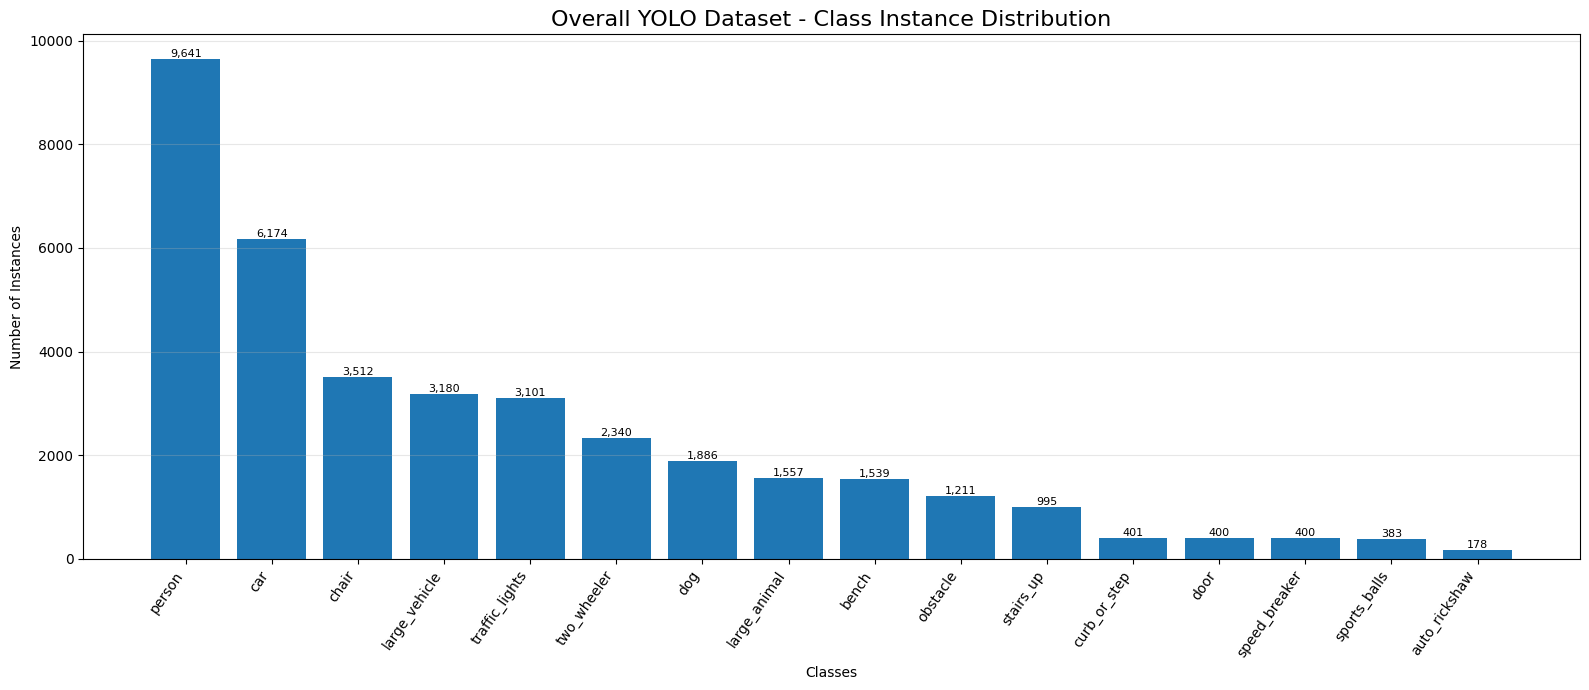

Graph saved to: /content/drive/MyDrive/Hazard_Detection/preprocessing_analysis_reports/overall_class_distribution.png


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

REPORT_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/"
    "preprocessing_analysis_reports"
)

# Load the existing CSV
df = pd.read_csv(
    REPORT_DIR / "overall_class_totals.csv"
)

# Sort by instance count
df = df.sort_values(
    "total_instances",
    ascending=False
)

# Remove classes with zero instances
df = df[df["total_instances"] > 0]

# Create bar graph
plt.figure(figsize=(16, 7))

bars = plt.bar(
    df["class_name"],
    df["total_instances"]
)

plt.title(
    "Overall YOLO Dataset - Class Instance Distribution",
    fontsize=16
)

plt.xlabel("Classes")
plt.ylabel("Number of Instances")

plt.xticks(rotation=55, ha="right")

# Display values above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save graph
output_path = REPORT_DIR / "overall_class_distribution.png"

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Graph saved to:", output_path)


In [ ]:

from pathlib import Path
import shutil

# ==================================================
# CONFIGURATION
# ==================================================

ROOT = Path(
    "/content/drive/MyDrive/Hazard_Detection"
)

POTHOLE_DATASET = (
    ROOT / "raw_datasets" / "potholes_kaggle" / "YOLO"
)

BACKUP_DIR = (
    ROOT / "preprocessing_analysis_reports" /
    "potholes_labels_backup_before_remap"
)

OLD_ID = "0"
NEW_ID = "7"

SPLITS = ["train", "val", "valid", "test"]


# ==================================================
# 1. FIND LABEL DIRECTORIES
# ==================================================

label_dirs = []

# Layout A: labels/train
if (POTHOLE_DATASET / "labels").is_dir():

    for split in SPLITS:

        folder = POTHOLE_DATASET / "labels" / split

        if folder.is_dir():
            label_dirs.append(folder)

# Layout B: train/labels
for split in SPLITS:

    folder = POTHOLE_DATASET / split / "labels"

    if folder.is_dir() and folder not in label_dirs:
        label_dirs.append(folder)

if not label_dirs:
    raise FileNotFoundError(
        "No label directories found. Check the dataset path."
    )

print("Label directories found:")

for folder in label_dirs:
    print(folder)


# ==================================================
# 2. COLLECT LABEL FILES
# ==================================================

label_files = []

for folder in label_dirs:
    label_files.extend(folder.glob("*.txt"))

print("\nTotal label files:", len(label_files))


# ==================================================
# 3. CHECK WHETHER REMAP IS POSSIBLE
# ==================================================

old_id_count = 0
new_id_count = 0

for file in label_files:

    with open(file, "r") as f:

        for line in f:

            parts = line.strip().split()

            if not parts:
                continue

            if parts[0] == OLD_ID:
                old_id_count += 1

            elif parts[0] == NEW_ID:
                new_id_count += 1

print("\nBefore remapping:")
print("Class 0 annotations:", old_id_count)
print("Class 7 annotations:", new_id_count)

if old_id_count == 0:
    raise RuntimeError(
        "No class 0 annotations found. "
        "Stopping to avoid an unnecessary remap."
    )


# ==================================================
# 4. BACKUP ORIGINAL LABEL FILES
# ==================================================

if BACKUP_DIR.exists():

    raise FileExistsError(
        f"Backup already exists: {BACKUP_DIR}\n"
        "Stopping to prevent overwriting the backup."
    )

BACKUP_DIR.mkdir(parents=True)

for folder in label_dirs:

    relative_folder = folder.relative_to(POTHOLE_DATASET)

    backup_folder = BACKUP_DIR / relative_folder

    backup_folder.mkdir(parents=True, exist_ok=True)

    for file in folder.glob("*.txt"):

        shutil.copy2(
            file,
            backup_folder / file.name
        )

print("\nBackup completed:")
print(BACKUP_DIR)


# ==================================================
# 5. REMAP CLASS 0 -> CLASS 7
# ==================================================

changed_files = 0
changed_annotations = 0

for file in label_files:

    new_lines = []
    file_changed = False

    with open(file, "r") as f:
        lines = f.readlines()

    for line in lines:

        parts = line.strip().split()

        if not parts:
            new_lines.append(line)
            continue

        if parts[0] == OLD_ID:

            parts[0] = NEW_ID

            new_lines.append(" ".join(parts) + "\n")

            changed_annotations += 1
            file_changed = True

        else:
            new_lines.append(line)

    if file_changed:

        with open(file, "w") as f:
            f.writelines(new_lines)

        changed_files += 1


# ==================================================
# 6. VERIFY REMAPPING
# ==================================================

remaining_old_id = 0
final_new_id = 0

for file in label_files:

    with open(file, "r") as f:

        for line in f:

            parts = line.strip().split()

            if not parts:
                continue

            if parts[0] == OLD_ID:
                remaining_old_id += 1

            elif parts[0] == NEW_ID:
                final_new_id += 1


# ==================================================
# 7. FINAL REPORT
# ==================================================

print("\n" + "=" * 60)
print("POTHOLE REMAPPING REPORT")
print("=" * 60)

print("Changed files:", changed_files)
print("Changed annotations:", changed_annotations)

print("\nFinal class 0 annotations:", remaining_old_id)
print("Final class 7 annotations:", final_new_id)

if remaining_old_id == 0:

    print("\nSUCCESS: All class 0 annotations were remapped to 7.")

else:

    print("\nWARNING: Some class 0 annotations remain.")

print("\nOriginal labels backed up at:")
print(BACKUP_DIR)


Label directories found:
/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO/labels/train
/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO/labels/val
/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO/labels/test

Total label files: 195

Before remapping:
Class 0 annotations: 508
Class 7 annotations: 0

Backup completed:
/content/drive/MyDrive/Hazard_Detection/preprocessing_analysis_reports/potholes_labels_backup_before_remap

POTHOLE REMAPPING REPORT
Changed files: 192
Changed annotations: 508

Final class 0 annotations: 0
Final class 7 annotations: 508

SUCCESS: All class 0 annotations were remapped to 7.

Original labels backed up at:
/content/drive/MyDrive/Hazard_Detection/preprocessing_analysis_reports/potholes_labels_backup_before_remap


MASTER CLASS CONFIGURATION
  0 : person
  1 : two_wheeler
  2 : car
  3 : auto_rickshaw
  4 : large_vehicle
  5 : large_animal
  6 : dog
  7 : pothole
  8 : open_drain
  9 : speed_breaker
 10 : stairs_up
 11 : stairs_down
 12 : curb_or_step
 13 : obstacle
 14 : vendor_stall
 15 : bench
 16 : chair
 17 : door
 18 : sports_balls
 19 : traffic_lights
 20 : other_hazards

Number of master classes: 21

STARTING DATASET ANALYSIS

---------------------------------------------------------------------------
[1/8] YOLO
/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO

  Analysing train...
    Images: 156
    Valid annotations: 442
    Empty labels: 1
    Missing labels: 0
    Orphan labels: 0
    Invalid boxes: 0

  Analysing valid...
    Images: 19
    Valid annotations: 45
    Empty labels: 0
    Missing labels: 0
    Orphan labels: 0
    Invalid boxes: 0

  Analysing test...
    Images: 20
    Valid annotations: 27
    Empty labels: 1
    Missing labels: 0
    Orphan 

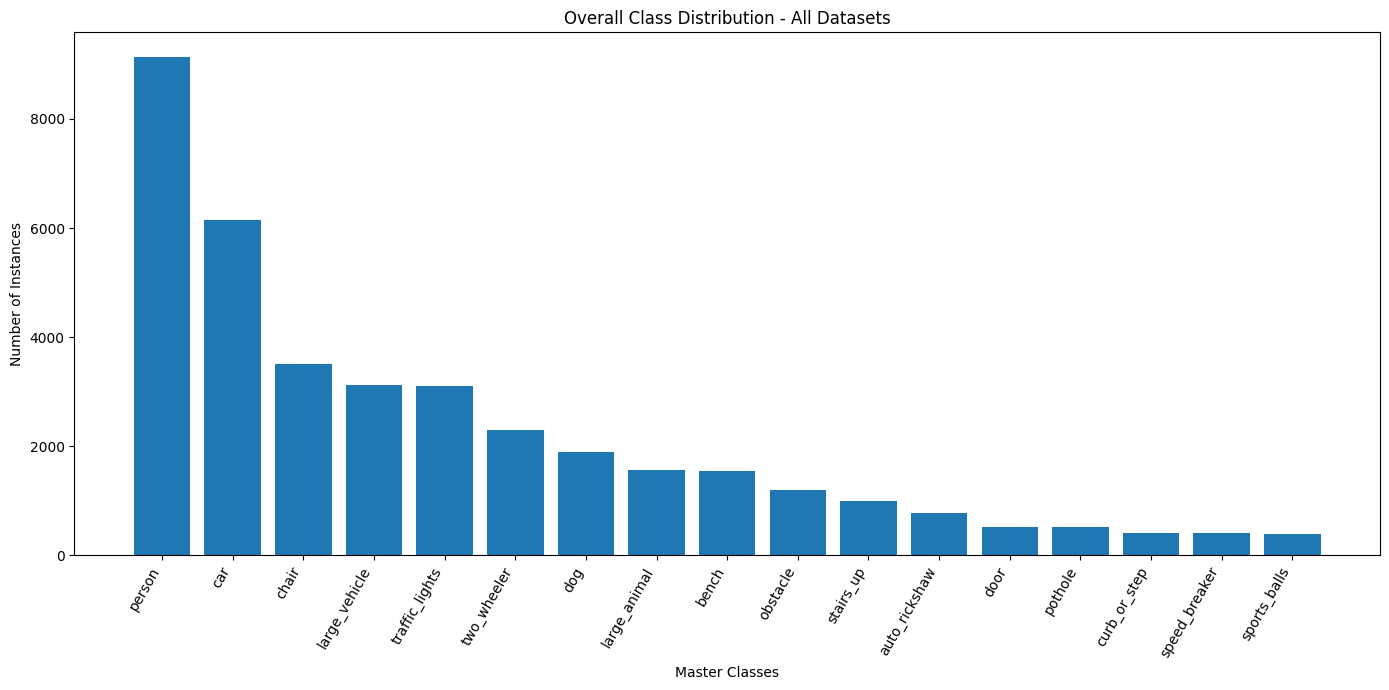

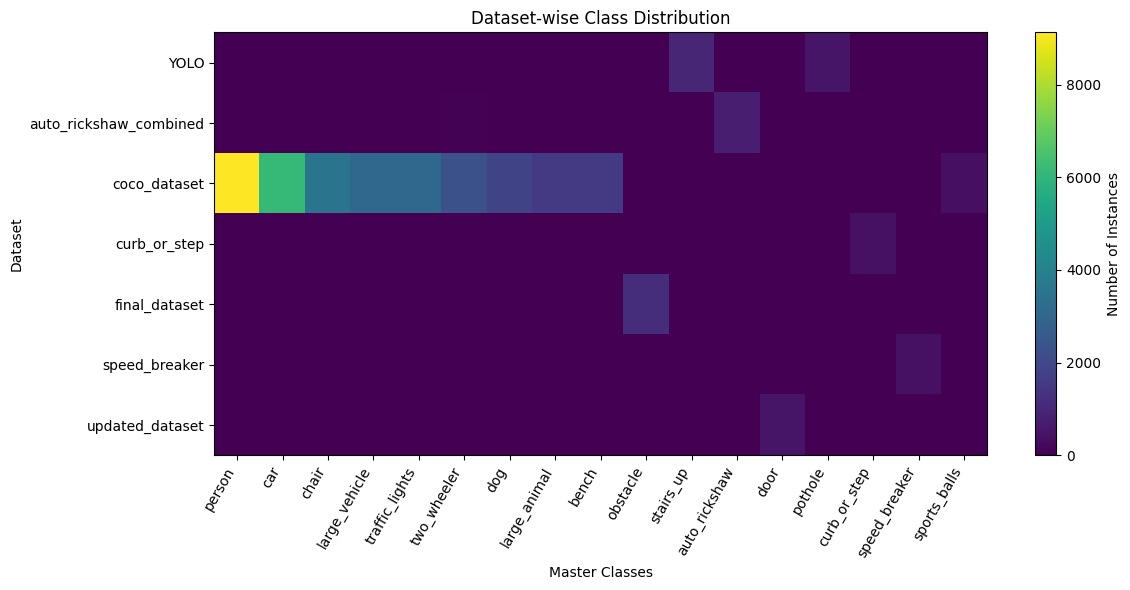

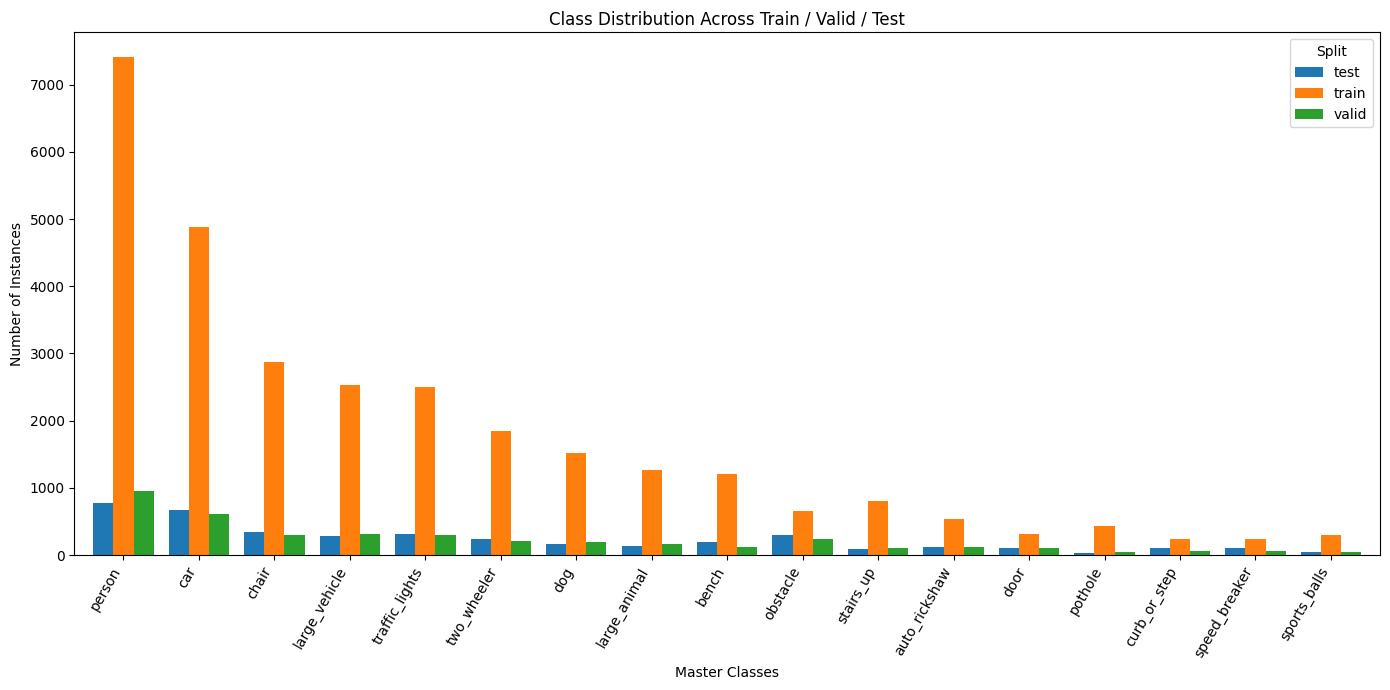

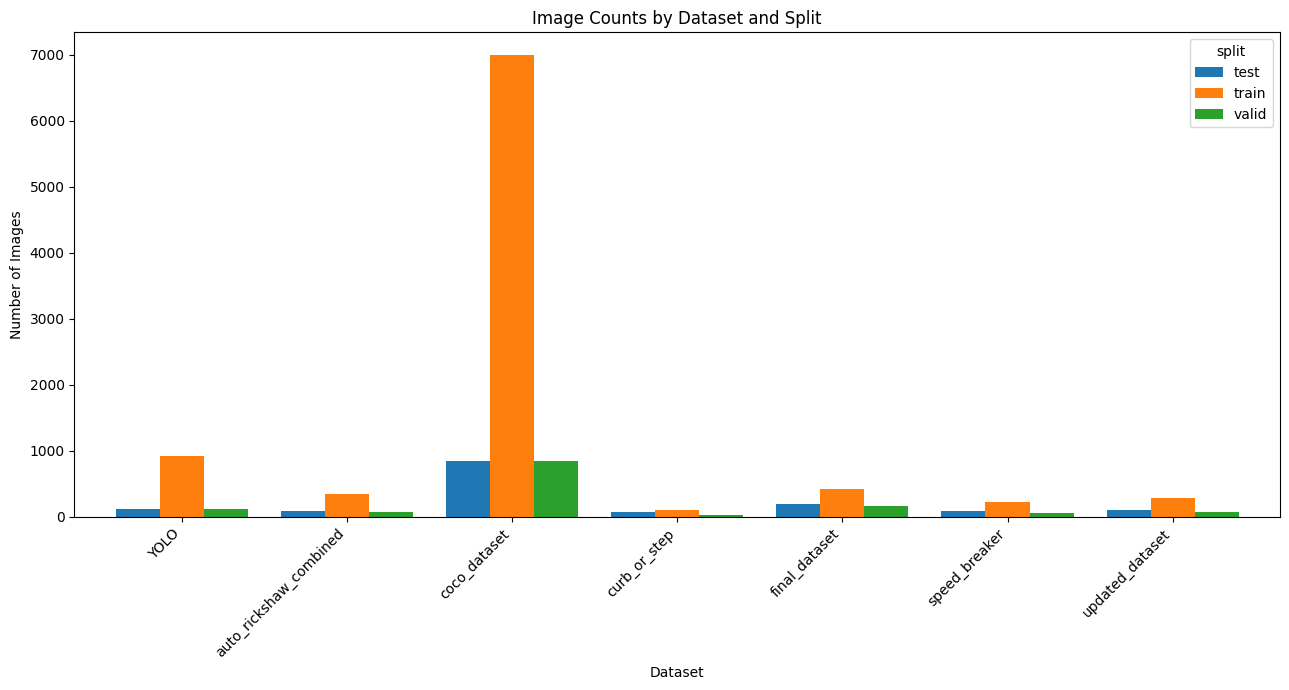

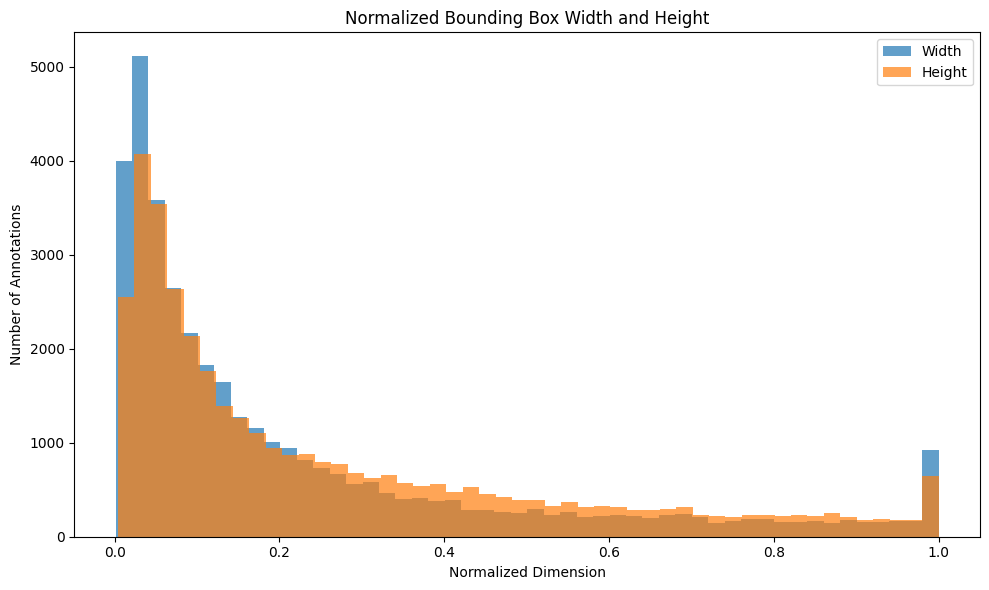

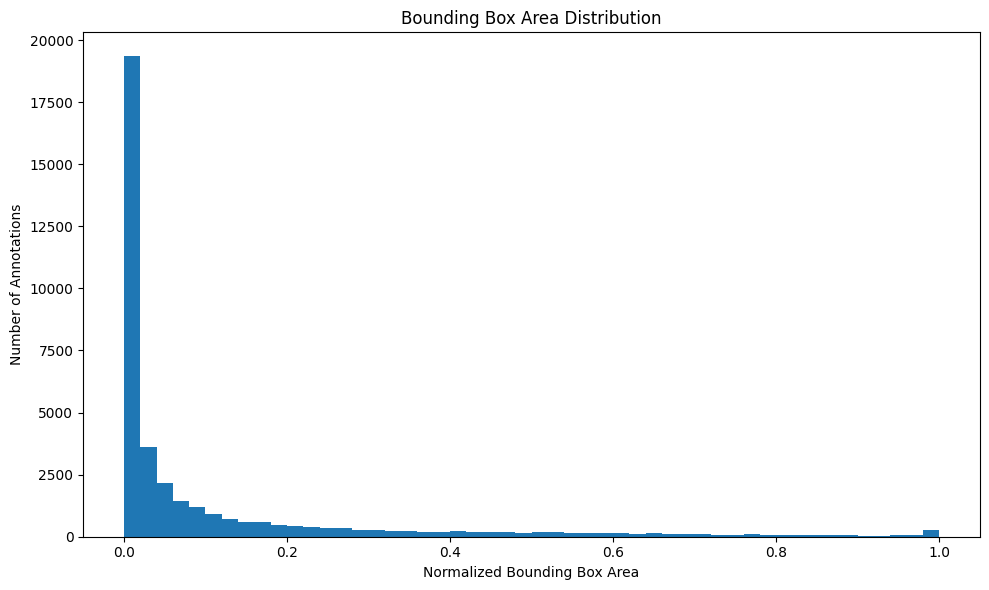

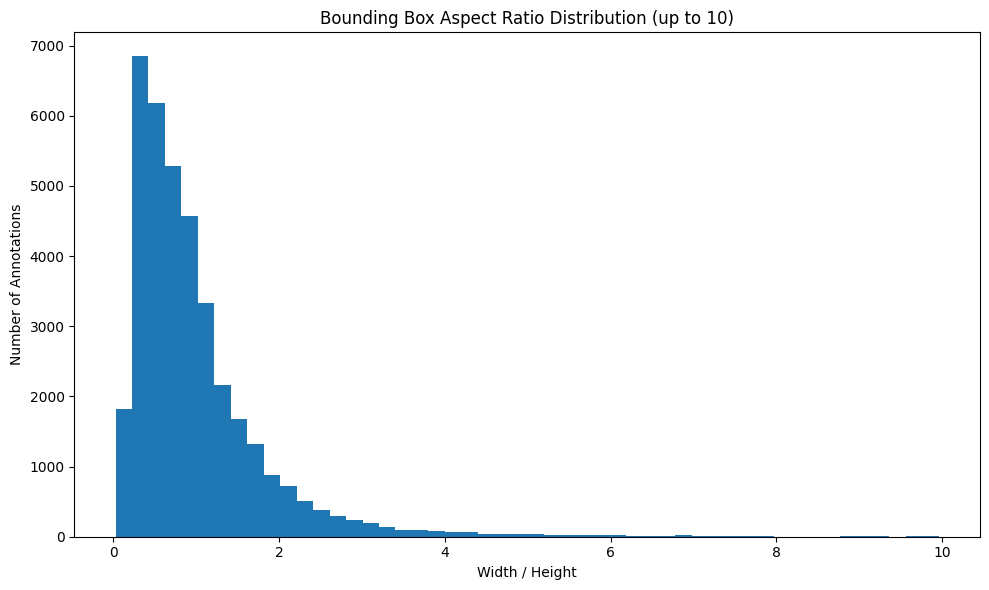

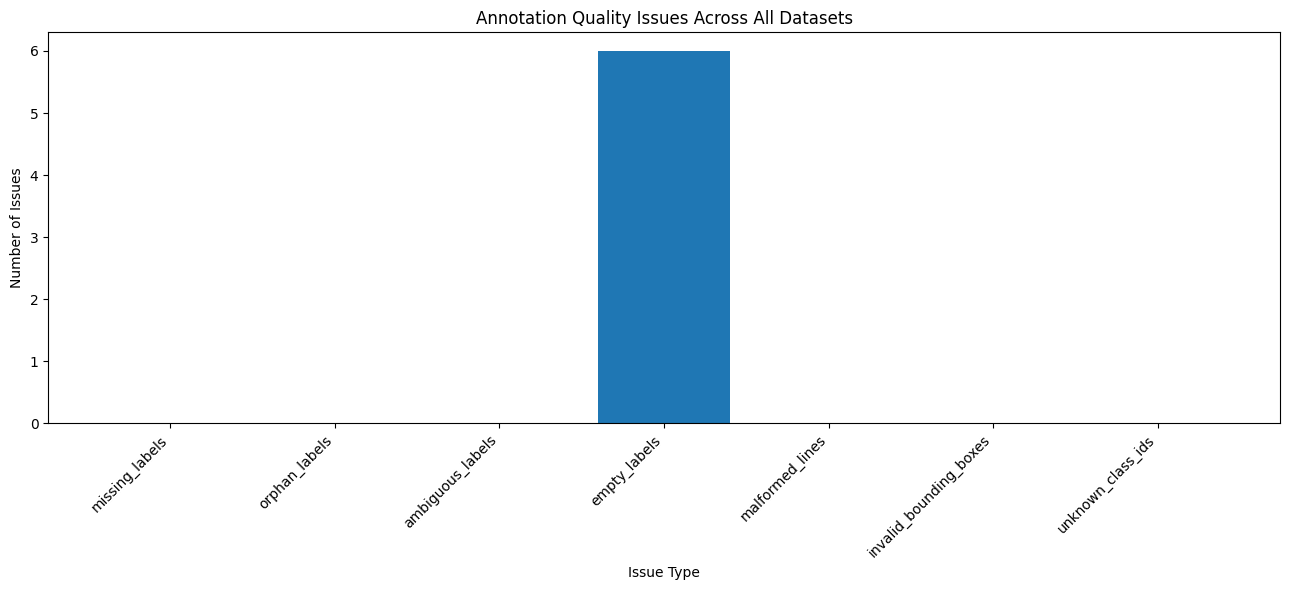


FINAL DATASET ANALYSIS

DATASET OVERVIEW
Datasets configured: 8
Existing datasets: 8
Total images: 12190
Total valid annotations: 37488
Total class instances: 37488

CLASS INSTANCE COUNTS
  0 person                        9133
  2 car                           6153
 16 chair                         3512
  4 large_vehicle                 3123
 19 traffic_lights                3101
  1 two_wheeler                   2298
  6 dog                           1886
  5 large_animal                  1557
 15 bench                         1539
 13 obstacle                      1202
 10 stairs_up                      995
  3 auto_rickshaw                  777
 17 door                           520
  7 pothole                        508
 12 curb_or_step                   401
  9 speed_breaker                  400
 18 sports_balls                   383
  8 open_drain                       0
 11 stairs_down                      0
 14 vendor_stall                     0
 20 other_hazards              

In [11]:

# =====================================================================
# COMPLETE YOLO DATASET PREPROCESSING ANALYSIS
# Optimized, incremental reporting, CSVs + graphs
#
# Uses prepared datasets only.
# Does NOT move, rename, delete, or modify dataset files.
# =====================================================================

!pip -q install pyyaml pandas matplotlib

import os
import csv
import yaml
import math
import statistics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter, defaultdict

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT = Path("/content/drive/MyDrive/Hazard_Detection")

MASTER_YAML = PROJECT / "master_class" / "classes.yaml"

REPORT_DIR = PROJECT / "preprocessing_analysis_reports"
GRAPH_DIR = REPORT_DIR / "graphs"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

# Only approved, prepared datasets.
# Do not add raw source folders here.

DATASET_PATHS = [
    "raw_datasets/potholes_kaggle/YOLO",
    "raw_datasets/coco_dataset",
    "raw_datasets/auto_rickshaw_combined",
    "raw_datasets/stairs/kaggle_1/final stairs/YOLO",
    "raw_datasets/speed_breaker",
    "raw_datasets/curb_or_step",
    "raw_datasets/obstacle/final_dataset",
    "raw_datasets/doors/updated_dataset",
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

SPLIT_NAMES = ["train", "valid", "test"]

# Save intermediate CSV reports after each dataset split.
INCREMENTAL_SAVE = True

# =====================================================================
# 2. LOAD MASTER CLASS FILE
# =====================================================================

if not MASTER_YAML.exists():
    raise FileNotFoundError(f"Master YAML not found: {MASTER_YAML}")

with open(MASTER_YAML, "r") as f:
    master_data = yaml.safe_load(f)

raw_names = master_data.get("names", {})

if isinstance(raw_names, list):
    CLASS_NAMES = {
        i: str(name) for i, name in enumerate(raw_names)
    }
else:
    CLASS_NAMES = {
        int(k): str(v) for k, v in raw_names.items()
    }

NUM_CLASSES = len(CLASS_NAMES)

print("=" * 75)
print("MASTER CLASS CONFIGURATION")
print("=" * 75)

for class_id in sorted(CLASS_NAMES):
    print(f"{class_id:>3} : {CLASS_NAMES[class_id]}")

print("\nNumber of master classes:", NUM_CLASSES)

# =====================================================================
# 3. HELPER FUNCTIONS
# =====================================================================

def find_split_directories(root, split):
    """
    Supports both common YOLO layouts:

    root/train/images + root/train/labels

    root/images/train + root/labels/train

    Also supports valid or val.
    """

    aliases = [split]

    if split == "valid":
        aliases = ["valid", "val"]

    candidates = []

    for alias in aliases:

        candidates.extend([
            (
                root / alias / "images",
                root / alias / "labels"
            ),
            (
                root / "images" / alias,
                root / "labels" / alias
            )
        ])

    for image_dir, label_dir in candidates:

        if image_dir.exists() and label_dir.exists():
            return image_dir, label_dir

    return None, None


def list_images(image_dir):
    if image_dir is None:
        return []

    return sorted([
        p for p in image_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ])


def list_labels(label_dir):
    if label_dir is None:
        return []

    return sorted([
        p for p in label_dir.rglob("*.txt")
        if p.is_file()
    ])


def resolve_label(image_path, image_dir, label_dir, labels_by_stem):
    """
    First tries matching relative paths.
    Falls back to unique filename stems.
    """

    relative = image_path.relative_to(image_dir)
    expected = (label_dir / relative).with_suffix(".txt")

    if expected.exists():
        return expected

    candidates = labels_by_stem.get(image_path.stem, [])

    if len(candidates) == 1:
        return candidates[0]

    if len(candidates) > 1:
        return "AMBIGUOUS"

    return None


def valid_bbox(x, y, w, h):
    return (
        0 <= x <= 1
        and 0 <= y <= 1
        and 0 < w <= 1
        and 0 < h <= 1
        and x - w / 2 >= -1e-6
        and x + w / 2 <= 1 + 1e-6
        and y - h / 2 >= -1e-6
        and y + h / 2 <= 1 + 1e-6
    )


def save_dataframe(data, filename):
    pd.DataFrame(data).to_csv(
        REPORT_DIR / filename,
        index=False
    )


# =====================================================================
# 4. REPORT STORAGE
# =====================================================================

discovery_rows = []
split_summary_rows = []
class_count_rows = []
dataset_class_rows = []
split_class_rows = []
bbox_rows = []
quality_rows = []

overall_class_counter = Counter()
dataset_class_counter = defaultdict(Counter)
split_class_counter = defaultdict(Counter)

all_bbox_widths = []
all_bbox_heights = []
all_bbox_areas = []
all_bbox_aspects = []

# =====================================================================
# 5. ANALYSE EACH DATASET
# =====================================================================

print("\n" + "=" * 75)
print("STARTING DATASET ANALYSIS")
print("=" * 75)

for dataset_index, relative_path in enumerate(DATASET_PATHS, 1):

    dataset_root = PROJECT / relative_path
    dataset_name = Path(relative_path).name

    print("\n" + "-" * 75)
    print(f"[{dataset_index}/{len(DATASET_PATHS)}] {dataset_name}")
    print(dataset_root)

    if not dataset_root.exists():

        print("WARNING: Dataset folder does not exist.")

        discovery_rows.append({
            "dataset": dataset_name,
            "path": str(dataset_root),
            "exists": False,
            "available_splits": ""
        })

        continue

    available_splits = []

    for split in SPLIT_NAMES:

        image_dir, label_dir = find_split_directories(
            dataset_root, split
        )

        if image_dir is not None:
            available_splits.append(split)

    discovery_rows.append({
        "dataset": dataset_name,
        "path": str(dataset_root),
        "exists": True,
        "available_splits": ", ".join(available_splits)
    })

    if not available_splits:
        print("WARNING: No recognized YOLO split directories found.")
        continue

    # ---------------------------------------------------------------
    # Analyse each split
    # ---------------------------------------------------------------

    for split in available_splits:

        print(f"\n  Analysing {split}...")

        image_dir, label_dir = find_split_directories(
            dataset_root, split
        )

        images = list_images(image_dir)
        labels = list_labels(label_dir)

        labels_by_stem = defaultdict(list)

        for label in labels:
            labels_by_stem[label.stem].append(label)

        matched_label_paths = set()

        # Quality counters
        missing_labels = 0
        ambiguous_labels = 0
        empty_labels = 0
        malformed_lines = 0
        invalid_boxes = 0
        unknown_classes = 0
        valid_annotations = 0

        image_count = len(images)
        labelled_images = 0

        class_counter = Counter()

        bbox_widths = []
        bbox_heights = []
        bbox_areas = []
        bbox_aspects = []

        for image_path in images:

            label_path = resolve_label(
                image_path,
                image_dir,
                label_dir,
                labels_by_stem
            )

            if label_path == "AMBIGUOUS":
                ambiguous_labels += 1
                continue

            if label_path is None:
                missing_labels += 1
                continue

            matched_label_paths.add(label_path)

            try:
                with open(label_path, "r") as f:
                    lines = f.readlines()

            except Exception:
                malformed_lines += 1
                continue

            nonempty_lines = [
                line.strip()
                for line in lines
                if line.strip()
            ]

            if not nonempty_lines:
                empty_labels += 1
                continue

            labelled_images += 1

            for line in nonempty_lines:

                parts = line.split()

                if len(parts) != 5:
                    malformed_lines += 1
                    continue

                try:
                    class_id = int(float(parts[0]))
                    x, y, w, h = map(float, parts[1:])

                except Exception:
                    malformed_lines += 1
                    continue

                if class_id not in CLASS_NAMES:
                    unknown_classes += 1
                    continue

                if not all(math.isfinite(v) for v in [x, y, w, h]):
                    invalid_boxes += 1
                    continue

                if not valid_bbox(x, y, w, h):
                    invalid_boxes += 1
                    continue

                # Valid annotation
                valid_annotations += 1
                class_counter[class_id] += 1

                area = w * h
                aspect = w / h

                bbox_widths.append(w)
                bbox_heights.append(h)
                bbox_areas.append(area)
                bbox_aspects.append(aspect)

                all_bbox_widths.append(w)
                all_bbox_heights.append(h)
                all_bbox_areas.append(area)
                all_bbox_aspects.append(aspect)

        # Count labels without a matching image.
        orphan_labels = len(set(labels) - matched_label_paths)

        # -----------------------------------------------------------
        # Save class-level results
        # -----------------------------------------------------------

        for class_id, count in sorted(class_counter.items()):

            class_name = CLASS_NAMES[class_id]

            class_count_rows.append({
                "dataset": dataset_name,
                "split": split,
                "class_id": class_id,
                "class_name": class_name,
                "instances": count
            })

            dataset_class_counter[dataset_name][class_id] += count
            split_class_counter[split][class_id] += count
            overall_class_counter[class_id] += count

        # -----------------------------------------------------------
        # Dataset/split summary
        # -----------------------------------------------------------

        split_summary_rows.append({
            "dataset": dataset_name,
            "split": split,
            "images": image_count,
            "label_files": len(labels),
            "images_with_annotations": labelled_images,
            "valid_annotations": valid_annotations,
            "missing_labels": missing_labels,
            "orphan_labels": orphan_labels,
            "empty_labels": empty_labels
        })

        # -----------------------------------------------------------
        # Annotation quality
        # -----------------------------------------------------------

        quality_rows.append({
            "dataset": dataset_name,
            "split": split,
            "missing_labels": missing_labels,
            "orphan_labels": orphan_labels,
            "ambiguous_labels": ambiguous_labels,
            "empty_labels": empty_labels,
            "malformed_lines": malformed_lines,
            "invalid_bounding_boxes": invalid_boxes,
            "unknown_class_ids": unknown_classes,
            "valid_annotations": valid_annotations
        })

        # -----------------------------------------------------------
        # Bounding box statistics
        # -----------------------------------------------------------

        def stats(values):
            if not values:
                return {
                    "mean": np.nan,
                    "median": np.nan,
                    "min": np.nan,
                    "max": np.nan
                }

            return {
                "mean": float(np.mean(values)),
                "median": float(np.median(values)),
                "min": float(np.min(values)),
                "max": float(np.max(values))
            }

        width_stats = stats(bbox_widths)
        height_stats = stats(bbox_heights)
        area_stats = stats(bbox_areas)
        aspect_stats = stats(bbox_aspects)

        bbox_rows.append({
            "dataset": dataset_name,
            "split": split,
            "bbox_count": valid_annotations,

            "width_mean": width_stats["mean"],
            "width_median": width_stats["median"],

            "height_mean": height_stats["mean"],
            "height_median": height_stats["median"],

            "area_mean": area_stats["mean"],
            "area_median": area_stats["median"],

            "aspect_mean": aspect_stats["mean"],
            "aspect_median": aspect_stats["median"],

            "width_min": width_stats["min"],
            "width_max": width_stats["max"],

            "height_min": height_stats["min"],
            "height_max": height_stats["max"],

            "area_min": area_stats["min"],
            "area_max": area_stats["max"]
        })

        print("    Images:", image_count)
        print("    Valid annotations:", valid_annotations)
        print("    Empty labels:", empty_labels)
        print("    Missing labels:", missing_labels)
        print("    Orphan labels:", orphan_labels)
        print("    Invalid boxes:", invalid_boxes)

        # -----------------------------------------------------------
        # Incremental report saving
        # -----------------------------------------------------------

        if INCREMENTAL_SAVE:

            save_dataframe(
                discovery_rows, "dataset_discovery.csv"
            )

            save_dataframe(
                split_summary_rows, "dataset_split_summary.csv"
            )

            save_dataframe(
                class_count_rows, "class_instance_counts.csv"
            )

            save_dataframe(
                quality_rows, "annotation_quality_report.csv"
            )

            save_dataframe(
                bbox_rows, "bounding_box_statistics.csv"
            )


# =====================================================================
# 6. BUILD AGGREGATED REPORTS
# =====================================================================

print("\n" + "=" * 75)
print("BUILDING AGGREGATED REPORTS")
print("=" * 75)

overall_class_rows = []

for class_id in sorted(CLASS_NAMES):

    overall_class_rows.append({
        "class_id": class_id,
        "class_name": CLASS_NAMES[class_id],
        "instances": overall_class_counter[class_id]
    })


dataset_class_totals = []

for dataset_name, counter in dataset_class_counter.items():

    for class_id, count in sorted(counter.items()):

        dataset_class_totals.append({
            "dataset": dataset_name,
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
            "instances": count
        })


split_class_totals = []

for split, counter in split_class_counter.items():

    for class_id, count in sorted(counter.items()):

        split_class_totals.append({
            "split": split,
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
            "instances": count
        })


# =====================================================================
# 7. SAVE ALL CSV REPORTS
# =====================================================================

reports = {
    "dataset_discovery.csv": discovery_rows,
    "dataset_split_summary.csv": split_summary_rows,
    "class_instance_counts.csv": class_count_rows,
    "overall_class_totals.csv": overall_class_rows,
    "dataset_class_totals.csv": dataset_class_totals,
    "split_class_totals.csv": split_class_totals,
    "bounding_box_statistics.csv": bbox_rows,
    "annotation_quality_report.csv": quality_rows
}

for filename, rows in reports.items():

    pd.DataFrame(rows).to_csv(
        REPORT_DIR / filename,
        index=False
    )

print("CSV reports saved:", len(reports))


# =====================================================================
# 8. PREPARE DATAFRAMES FOR GRAPHS
# =====================================================================

overall_df = pd.DataFrame(overall_class_rows)
dataset_df = pd.DataFrame(dataset_class_totals)
split_df = pd.DataFrame(split_class_totals)
summary_df = pd.DataFrame(split_summary_rows)
bbox_df = pd.DataFrame(bbox_rows)
quality_df = pd.DataFrame(quality_rows)

# Exclude zero-instance classes from instance graphs.
overall_nonzero = overall_df[
    overall_df["instances"] > 0
].sort_values("instances", ascending=False)

# =====================================================================
# 9. GRAPH 1: OVERALL CLASS DISTRIBUTION
# =====================================================================

print("\nGenerating graphs...")

if not overall_nonzero.empty:

    plt.figure(figsize=(14, 7))

    plt.bar(
        overall_nonzero["class_name"],
        overall_nonzero["instances"]
    )

    plt.title("Overall Class Distribution - All Datasets")
    plt.xlabel("Master Classes")
    plt.ylabel("Number of Instances")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / "overall_class_distribution.png",
        dpi=200
    )

    plt.show()
    plt.close()


# =====================================================================
# 10. GRAPH 2: DATASET-WISE CLASS DISTRIBUTION
# =====================================================================

if not dataset_df.empty:

    pivot_dataset = dataset_df.pivot_table(
        index="dataset",
        columns="class_name",
        values="instances",
        aggfunc="sum",
        fill_value=0
    )

    # Keep only classes that appear at least once.
    pivot_dataset = pivot_dataset.loc[
        :, pivot_dataset.sum(axis=0).sort_values(
            ascending=False
        ).index
    ]

    # Heatmap-style graph.
    plt.figure(
        figsize=(
            max(12, len(pivot_dataset.columns) * 0.65),
            max(6, len(pivot_dataset.index) * 0.7)
        )
    )

    plt.imshow(
        pivot_dataset.values,
        aspect="auto"
    )

    plt.colorbar(label="Number of Instances")

    plt.xticks(
        range(len(pivot_dataset.columns)),
        pivot_dataset.columns,
        rotation=60,
        ha="right"
    )

    plt.yticks(
        range(len(pivot_dataset.index)),
        pivot_dataset.index
    )

    plt.title("Dataset-wise Class Distribution")
    plt.xlabel("Master Classes")
    plt.ylabel("Dataset")

    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / "dataset_wise_class_distribution.png",
        dpi=200
    )

    plt.show()
    plt.close()


# =====================================================================
# 11. GRAPH 3: SPLIT-WISE CLASS DISTRIBUTION
# =====================================================================

if not split_df.empty:

    pivot_split = split_df.pivot_table(
        index="class_name",
        columns="split",
        values="instances",
        aggfunc="sum",
        fill_value=0
    )

    pivot_split = pivot_split.loc[
        pivot_split.sum(axis=1).sort_values(
            ascending=False
        ).index
    ]

    pivot_split.plot(
        kind="bar",
        figsize=(14, 7),
        width=0.8
    )

    plt.title("Class Distribution Across Train / Valid / Test")
    plt.xlabel("Master Classes")
    plt.ylabel("Number of Instances")
    plt.xticks(rotation=60, ha="right")
    plt.legend(title="Split")
    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / "split_wise_class_distribution.png",
        dpi=200
    )

    plt.show()
    plt.close()


# =====================================================================
# 12. GRAPH 4: IMAGE COUNTS BY DATASET AND SPLIT
# =====================================================================

if not summary_df.empty:

    pivot_images = summary_df.pivot_table(
        index="dataset",
        columns="split",
        values="images",
        aggfunc="sum",
        fill_value=0
    )

    pivot_images.plot(
        kind="bar",
        figsize=(13, 7),
        width=0.8
    )

    plt.title("Image Counts by Dataset and Split")
    plt.xlabel("Dataset")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / "dataset_split_image_counts.png",
        dpi=200
    )

    plt.show()
    plt.close()


# =====================================================================
# 13. GRAPH 5: BOUNDING BOX WIDTH / HEIGHT
# =====================================================================

if all_bbox_widths:

    plt.figure(figsize=(10, 6))

    plt.hist(
        all_bbox_widths,
        bins=50,
        alpha=0.7,
        label="Width"
    )

    plt.hist(
        all_bbox_heights,
        bins=50,
        alpha=0.7,
        label="Height"
    )

    plt.title("Normalized Bounding Box Width and Height")
    plt.xlabel("Normalized Dimension")
    plt.ylabel("Number of Annotations")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / "bbox_width_height_distribution.png",
        dpi=200
    )

    plt.show()
    plt.close()


# =====================================================================
# 14. GRAPH 6: BOUNDING BOX AREA
# =====================================================================

if all_bbox_areas:

    plt.figure(figsize=(10, 6))

    plt.hist(
        all_bbox_areas,
        bins=50
    )

    plt.title("Bounding Box Area Distribution")
    plt.xlabel("Normalized Bounding Box Area")
    plt.ylabel("Number of Annotations")
    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / "bbox_area_distribution.png",
        dpi=200
    )

    plt.show()
    plt.close()


# =====================================================================
# 15. GRAPH 7: BOUNDING BOX ASPECT RATIO
# =====================================================================

if all_bbox_aspects:

    # Cap displayed values to keep extreme ratios from hiding
    # the main distribution. Original statistics remain unchanged.
    display_aspects = [
        x for x in all_bbox_aspects
        if x <= 10
    ]

    plt.figure(figsize=(10, 6))

    plt.hist(
        display_aspects,
        bins=50
    )

    plt.title("Bounding Box Aspect Ratio Distribution (up to 10)")
    plt.xlabel("Width / Height")
    plt.ylabel("Number of Annotations")
    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / "bbox_aspect_ratio_distribution.png",
        dpi=200
    )

    plt.show()
    plt.close()


# =====================================================================
# 16. GRAPH 8: ANNOTATION QUALITY
# =====================================================================

if not quality_df.empty:

    issue_columns = [
        "missing_labels",
        "orphan_labels",
        "ambiguous_labels",
        "empty_labels",
        "malformed_lines",
        "invalid_bounding_boxes",
        "unknown_class_ids"
    ]

    quality_totals = quality_df[issue_columns].sum()

    plt.figure(figsize=(13, 6))

    plt.bar(
        quality_totals.index,
        quality_totals.values
    )

    plt.title("Annotation Quality Issues Across All Datasets")
    plt.xlabel("Issue Type")
    plt.ylabel("Number of Issues")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / "annotation_quality_issues.png",
        dpi=200
    )

    plt.show()
    plt.close()


# =====================================================================
# 17. FINAL NUMERICAL ANALYSIS
# =====================================================================

total_images = (
    summary_df["images"].sum()
    if not summary_df.empty else 0
)

total_instances = sum(overall_class_counter.values())

total_valid = (
    summary_df["valid_annotations"].sum()
    if not summary_df.empty else 0
)

total_issues = (
    quality_df[
        [
            "missing_labels",
            "orphan_labels",
            "ambiguous_labels",
            "malformed_lines",
            "invalid_bounding_boxes",
            "unknown_class_ids"
        ]
    ].sum().sum()
    if not quality_df.empty else 0
)

print("\n" + "=" * 75)
print("FINAL DATASET ANALYSIS")
print("=" * 75)

print("\nDATASET OVERVIEW")
print("Datasets configured:", len(DATASET_PATHS))
print("Existing datasets:", sum(
    1 for r in discovery_rows if r["exists"]
))
print("Total images:", total_images)
print("Total valid annotations:", total_valid)
print("Total class instances:", total_instances)

print("\nCLASS INSTANCE COUNTS")

for row in sorted(
    overall_class_rows,
    key=lambda x: x["instances"],
    reverse=True
):

    print(
        f"{row['class_id']:>3} "
        f"{row['class_name']:<25} "
        f"{row['instances']:>8}"
    )

print("\nSPLIT SUMMARY")

if not summary_df.empty:
    print(
        summary_df.groupby("split")[
            ["images", "valid_annotations"]
        ].sum().to_string()
    )

print("\nANNOTATION QUALITY TOTALS")

if not quality_df.empty:
    print(
        quality_df[
            [
                "missing_labels",
                "orphan_labels",
                "ambiguous_labels",
                "empty_labels",
                "malformed_lines",
                "invalid_bounding_boxes",
                "unknown_class_ids"
            ]
        ].sum().to_string()
    )

print("\nOVERALL BOUNDING BOX STATISTICS")

if all_bbox_widths:

    print("Mean width:", round(float(np.mean(all_bbox_widths)), 5))
    print("Mean height:", round(float(np.mean(all_bbox_heights)), 5))
    print("Mean area:", round(float(np.mean(all_bbox_areas)), 5))
    print("Mean aspect ratio:", round(float(np.mean(all_bbox_aspects)), 5))

print("\n" + "=" * 75)
print("ALL REPORTS SAVED")
print("=" * 75)

print("\nCSV REPORTS:")
for filename in reports:
    print(REPORT_DIR / filename)

print("\nGRAPHS:")
for graph in sorted(GRAPH_DIR.glob("*.png")):
    print(graph)

print("\nREPORT DIRECTORY:")
print(REPORT_DIR)

print("\nANALYSIS COMPLETE")
print("=" * 75)


In [14]:

# ================================================================
# FINAL DATASET MERGER
# 8 DATASETS -> ONE YOLO DATASET
# OLD 21 CLASSES -> NEW 17 CLASSES
# ================================================================

!pip -q install pyyaml

import os
import re
import csv
import yaml
import shutil
import hashlib
from pathlib import Path
from collections import Counter, defaultdict

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Hazard_Detection"
)

# Mount Drive if needed
from google.colab import drive
drive.mount("/content/drive")

DATASET_PATHS = [
    "raw_datasets/potholes_kaggle/YOLO",
    "raw_datasets/coco_dataset",
    "raw_datasets/auto_rickshaw_combined",
    "raw_datasets/stairs/kaggle_1/final stairs/YOLO",
    "raw_datasets/speed_breaker",
    "raw_datasets/curb_or_step",
    "raw_datasets/obstacle/final_dataset",
    "raw_datasets/doors/updated_dataset",
]

OUTPUT_ROOT = PROJECT_ROOT / "final_dataset"
MASTER_YAML = PROJECT_ROOT / "master_class" / "classes.yaml"

# Do not overwrite an existing output accidentally.
if OUTPUT_ROOT.exists():
    raise FileExistsError(
        f"\nOutput already exists:\n{OUTPUT_ROOT}\n"
        "Rename or move the existing folder before running again."
    )

# ------------------------------------------------
# 2. NEW MASTER CLASS LIST
# ------------------------------------------------

NEW_NAMES = {
    0: "person",
    1: "two_wheeler",
    2: "car",
    3: "auto_rickshaw",
    4: "large_vehicle",
    5: "large_animal",
    6: "dog",
    7: "pothole",
    8: "speed_breaker",
    9: "stairs",
    10: "curb_or_step",
    11: "obstacle",
    12: "bench",
    13: "chair",
    14: "door",
    15: "sports_balls",
    16: "traffic_lights",
}

# ------------------------------------------------
# 3. OLD CLASS ID -> NEW CLASS ID
# ------------------------------------------------

# Old master:
# 0 person
# 1 two_wheeler
# 2 car
# 3 auto_rickshaw
# 4 large_vehicle
# 5 large_animal
# 6 dog
# 7 pothole
# 8 open_drain
# 9 speed_breaker
# 10 stairs_up
# 11 stairs_down
# 12 curb_or_step
# 13 obstacle
# 14 vendor_stall
# 15 bench
# 16 chair
# 17 door
# 18 sports_balls
# 19 traffic_lights
# 20 other_hazards

CLASS_REMAP = {
    0: 0,
    1: 1,
    2: 2,
    3: 3,
    4: 4,
    5: 5,
    6: 6,
    7: 7,

    # 8 = open_drain: intentionally excluded
    9: 8,

    # Both stair directions become one class
    10: 9,
    11: 9,

    12: 10,
    13: 11,

    # 14 = vendor_stall: intentionally excluded
    15: 12,
    16: 13,
    17: 14,
    18: 15,
    19: 16,

    # 20 = other_hazards: intentionally excluded
}

EXCLUDED_OLD_IDS = {8, 14, 20}

# ------------------------------------------------
# 4. SPLIT AND IMAGE SETTINGS
# ------------------------------------------------

SPLIT_ALIASES = {
    "train": ["train"],
    "valid": ["valid", "val"],
    "test": ["test"],
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

# ------------------------------------------------
# 5. HELPER FUNCTIONS
# ------------------------------------------------

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


def safe_name(value):
    value = str(value).replace("\\", "_").replace("/", "_")
    value = re.sub(r"[^A-Za-z0-9_-]+", "_", value)
    return value.strip("_")


def find_split_directories(dataset_root, split_name):
    """
    Supports:
      dataset/train/images + dataset/train/labels
      dataset/images/train + dataset/labels/train
    """

    aliases = SPLIT_ALIASES[split_name]

    for alias in aliases:

        candidates = [
            (
                dataset_root / alias / "images",
                dataset_root / alias / "labels"
            ),
            (
                dataset_root / "images" / alias,
                dataset_root / "labels" / alias
            ),
        ]

        for image_dir, label_dir in candidates:
            if image_dir.is_dir() and label_dir.is_dir():
                return image_dir, label_dir

    return None, None


def find_label_for_image(image_path, image_dir, label_dir):
    relative_path = image_path.relative_to(image_dir)
    expected = label_dir / relative_path.with_suffix(".txt")

    if expected.exists():
        return expected

    # Fallback: match by filename stem, only if unambiguous.
    matches = list(label_dir.rglob(image_path.stem + ".txt"))

    if len(matches) == 1:
        return matches[0]

    if len(matches) > 1:
        raise RuntimeError(
            f"Ambiguous label match for image: {image_path}"
        )

    return None


def remap_label_file(label_path):
    """
    Returns remapped YOLO annotation lines.
    Rejects malformed labels, invalid class IDs and
    unexpected instances of excluded classes.
    """

    output_lines = []

    if label_path is None:
        raise RuntimeError("Missing label file.")

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line_number, line in enumerate(lines, start=1):

        line = line.strip()

        if not line:
            continue

        parts = line.split()

        if len(parts) != 5:
            raise ValueError(
                f"Malformed annotation: {label_path}, "
                f"line {line_number}: {line}"
            )

        try:
            old_class = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            raise ValueError(
                f"Non-numeric annotation: {label_path}, "
                f"line {line_number}"
            )

        if old_class in EXCLUDED_OLD_IDS:
            raise ValueError(
                f"Found excluded old class ID {old_class} "
                f"in {label_path}. "
                "Review this annotation before merging."
            )

        if old_class not in CLASS_REMAP:
            raise ValueError(
                f"Unknown old class ID {old_class} in {label_path}"
            )

        if not (
            0 <= x <= 1 and
            0 <= y <= 1 and
            0 < w <= 1 and
            0 < h <= 1 and
            x - w / 2 >= -1e-6 and
            y - h / 2 >= -1e-6 and
            x + w / 2 <= 1 + 1e-6 and
            y + h / 2 <= 1 + 1e-6
        ):
            raise ValueError(
                f"Invalid bounding box in {label_path}, "
                f"line {line_number}: {line}"
            )

        new_class = CLASS_REMAP[old_class]

        output_lines.append(
            f"{new_class} "
            f"{x:.8f} {y:.8f} {w:.8f} {h:.8f}"
        )

    return output_lines


# ------------------------------------------------
# 6. DISCOVER ALL SOURCE IMAGES AND LABELS
# ------------------------------------------------

print("=" * 70)
print("STEP 1: DISCOVERING SOURCE DATASETS")
print("=" * 70)

records = []
dataset_summary = []

for relative_dataset_path in DATASET_PATHS:

    dataset_root = PROJECT_ROOT / relative_dataset_path

    if not dataset_root.is_dir():
        raise FileNotFoundError(
            f"Dataset folder not found: {dataset_root}"
        )

    dataset_key = safe_name(relative_dataset_path)

    print(f"\nDataset: {relative_dataset_path}")

    for split_name in ["train", "valid", "test"]:

        image_dir, label_dir = find_split_directories(
            dataset_root, split_name
        )

        if image_dir is None:
            print(f"  {split_name}: split not found; skipping")
            continue

        images = sorted(
            p for p in image_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        print(f"  {split_name}: {len(images)} images")

        for image_path in images:

            label_path = find_label_for_image(
                image_path, image_dir, label_dir
            )

            if label_path is None:
                raise RuntimeError(
                    f"Missing label for image: {image_path}"
                )

            remapped_lines = remap_label_file(label_path)

            image_hash = sha256_file(image_path)

            relative_image = image_path.relative_to(image_dir)

            unique_stem = safe_name(
                str(relative_image.with_suffix(""))
            )

            output_filename = (
                f"{dataset_key}__{unique_stem}"
                f"{image_path.suffix.lower()}"
            )

            records.append({
                "dataset": relative_dataset_path,
                "dataset_key": dataset_key,
                "split": split_name,
                "image_path": image_path,
                "label_path": label_path,
                "image_hash": image_hash,
                "output_filename": output_filename,
                "label_lines": remapped_lines,
            })


# ------------------------------------------------
# 7. DUPLICATE AND LEAKAGE CHECK
# Automatically remove exact duplicates across splits.
# Prefer TRAIN, then VALID, then TEST.
# ------------------------------------------------

# ------------------------------------------------
# 7. DUPLICATE AND LEAKAGE CHECK
# Keep TRAIN copy first, then VALID, then TEST.
# For identical images, retain one complete annotation set.
# ------------------------------------------------

print("\n" + "=" * 70)
print("STEP 2: RESOLVING EXACT DUPLICATES")
print("=" * 70)

hash_groups = defaultdict(list)

for record in records:
    hash_groups[record["image_hash"]].append(record)

duplicates_to_skip = set()
duplicate_report = []

split_priority = {
    "train": 0,
    "valid": 1,
    "test": 2
}

for image_hash, group in hash_groups.items():

    if len(group) <= 1:
        continue

    group = sorted(
        group,
        key=lambda r: split_priority[r["split"]]
    )

    keeper = group[0]
    keeper_labels = sorted(keeper["label_lines"])

    for duplicate in group[1:]:

        duplicate_labels = sorted(duplicate["label_lines"])

        annotations_match = (
            keeper_labels == duplicate_labels
        )

        duplicates_to_skip.add(id(duplicate))

        duplicate_report.append({
            "hash": image_hash,
            "kept_split": keeper["split"],
            "skipped_split": duplicate["split"],
            "kept_image": str(keeper["image_path"]),
            "skipped_image": str(duplicate["image_path"]),
            "annotations_match": annotations_match,
            "kept_annotations": " | ".join(keeper_labels),
            "skipped_annotations": " | ".join(duplicate_labels),
        })

        print("\nDuplicate resolved:")
        print("  Kept split:", keeper["split"])
        print("  Kept image:", keeper["image_path"].name)
        print("  Skipped split:", duplicate["split"])
        print("  Skipped image:", duplicate["image_path"].name)
        print("  Annotations identical:", annotations_match)

        if not annotations_match:
            print("  WARNING: Different annotations.")
            print("  Retaining the selected copy's annotations only.")

print("\nDUPLICATE SUMMARY")
print("Duplicate copies skipped:", len(duplicates_to_skip))
print("Unique images remaining:", len(records) - len(duplicates_to_skip))
print("Conflicting annotation pairs:", sum(
    not r["annotations_match"] for r in duplicate_report
))


# ------------------------------------------------
# 8. PREPARE FINAL OUTPUT FOLDERS
# ------------------------------------------------

print("\n" + "=" * 70)
print("STEP 3: CREATING FINAL DATASET")
print("=" * 70)

for split_name in ["train", "valid", "test"]:
    (OUTPUT_ROOT / split_name / "images").mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT_ROOT / split_name / "labels").mkdir(
        parents=True, exist_ok=True
    )

class_counts = Counter()
split_image_counts = Counter()
split_annotation_counts = Counter()
dataset_counts = Counter()

used_output_names = set()

for index, record in enumerate(records, start=1):

    if id(record) in duplicates_to_skip:
        continue

    split_name = record["split"]

    filename = record["output_filename"]

    if filename in used_output_names:
        raise RuntimeError(
            f"Output filename collision: {filename}"
        )

    used_output_names.add(filename)

    output_image = (
        OUTPUT_ROOT / split_name / "images" / filename
    )

    output_label = (
        OUTPUT_ROOT / split_name / "labels" /
        (Path(filename).stem + ".txt")
    )

    shutil.copy2(record["image_path"], output_image)

    with open(output_label, "w") as f:
        if record["label_lines"]:
            f.write("\n".join(record["label_lines"]) + "\n")

    split_image_counts[split_name] += 1
    dataset_counts[record["dataset"]] += 1

    split_annotation_counts[split_name] += len(
        record["label_lines"]
    )

    for line in record["label_lines"]:
        class_id = int(line.split()[0])
        class_counts[class_id] += 1

    if index % 500 == 0:
        print(f"Processed source records: {index}/{len(records)}")

# ------------------------------------------------
# 9. WRITE MASTER CLASSES YAML
# ------------------------------------------------

MASTER_YAML.parent.mkdir(parents=True, exist_ok=True)

master_yaml_text = """names:
  0: person
  1: two_wheeler        # bicycle, scooter, motorcycle
  2: car
  3: auto_rickshaw
  4: large_vehicle      # bus, truck, tractors
  5: large_animal       # cow, horse
  6: dog
  7: pothole            # includes broken_pavement
  8: speed_breaker
  9: stairs
  10: curb_or_step
  11: obstacle          # barricade, pull-cart, trash_cans, cement_machinery
  12: bench
  13: chair
  14: door
  15: sports_balls
  16: traffic_lights
"""

with open(MASTER_YAML, "w") as f:
    f.write(master_yaml_text)

# ------------------------------------------------
# 10. WRITE FINAL YOLO DATA YAML
# ------------------------------------------------

data_yaml = {
    "path": str(OUTPUT_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(NEW_NAMES),
    "names": NEW_NAMES,
}

with open(OUTPUT_ROOT / "data.yaml", "w") as f:
    yaml.safe_dump(
        data_yaml,
        f,
        sort_keys=False,
        allow_unicode=True
    )

# ------------------------------------------------
# 11. SAVE MERGE REPORT
# ------------------------------------------------

report_path = OUTPUT_ROOT / "merge_report.csv"

with open(report_path, "w", newline="") as f:
    writer = csv.writer(f)

    writer.writerow([
        "class_id",
        "class_name",
        "instances"
    ])

    for class_id, class_name in NEW_NAMES.items():
        writer.writerow([
            class_id,
            class_name,
            class_counts[class_id]
        ])

duplicate_report_path = OUTPUT_ROOT / "same_split_duplicates_skipped.csv"

with open(duplicate_report_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "hash", "split", "skipped_image", "kept_image"
        ]
    )
    writer.writeheader()
    writer.writerows(duplicate_report)

# ------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL DATASET MERGE COMPLETE")
print("=" * 70)

print(f"\nOutput: {OUTPUT_ROOT}")

print("\nSPLIT IMAGE COUNTS")

for split_name in ["train", "valid", "test"]:
    print(
        f"{split_name:8s}: "
        f"{split_image_counts[split_name]:6d} images | "
        f"{split_annotation_counts[split_name]:6d} annotations"
    )

print("\nNEW CLASS INSTANCE COUNTS")

for class_id, class_name in NEW_NAMES.items():
    print(
        f"{class_id:2d} {class_name:20s}: "
        f"{class_counts[class_id]:6d}"
    )

print("\nTOTAL IMAGES:", sum(split_image_counts.values()))
print("TOTAL ANNOTATIONS:", sum(class_counts.values()))
print("CLASSES:", len(NEW_NAMES))

print("\nMASTER YAML:")
print(MASTER_YAML)

print("\nTRAINING YAML:")
print(OUTPUT_ROOT / "data.yaml")

print("\nMERGE REPORT:")
print(report_path)

print("\n" + "=" * 70)
print("READY FOR YOLO26n TRAINING")
print("=" * 70)


Streaming output truncated to the last 5000 lines.
  Skipped image: coco_6af5ef2da370bdebd60845ce.jpg
  Annotations identical: True

Duplicate resolved:
  Kept split: train
  Kept image: coco_6af5ed48a370bdebd6041a70.jpg
  Skipped split: train
  Skipped image: coco_6af5ef2da370bdebd60845d1.jpg
  Annotations identical: True

Duplicate resolved:
  Kept split: train
  Kept image: coco_6af5ed48a370bdebd6041a7e.jpg
  Skipped split: train
  Skipped image: coco_6af5ef2da370bdebd6084670.jpg
  Annotations identical: True

Duplicate resolved:
  Kept split: train
  Kept image: coco_6af5ed48a370bdebd6041b47.jpg
  Skipped split: train
  Skipped image: coco_6af5ef2da370bdebd6084689.jpg
  Annotations identical: True

Duplicate resolved:
  Kept split: train
  Kept image: coco_6af5ed48a370bdebd6041b53.jpg
  Skipped split: train
  Skipped image: coco_6af5ef2ea370bdebd608476d.jpg
  Annotations identical: True

Duplicate resolved:
  Kept split: train
  Kept image: coco_6af5ed48a370bdebd6041b58.jpg
  Skipp

ValueError: dict contains fields not in fieldnames: 'skipped_split', 'skipped_annotations', 'annotations_match', 'kept_annotations', 'kept_split'

In [15]:

# ================================================================
# DIAGNOSE WHERE THE 3,115 DUPLICATES COME FROM
# ================================================================

from collections import Counter, defaultdict
import pandas as pd

source_pair_counts = Counter()
split_pair_counts = Counter()
source_internal_counts = Counter()
conflicting_pairs = []

for image_hash, group in hash_groups.items():

    if len(group) <= 1:
        continue

    # Count duplicates within each source
    source_counts = Counter(r["dataset"] for r in group)

    for source, count in source_counts.items():
        if count > 1:
            source_internal_counts[source] += count - 1

    # Count pairs between different sources
    sources = sorted(set(r["dataset"] for r in group))

    if len(sources) > 1:
        for i in range(len(sources)):
            for j in range(i + 1, len(sources)):
                source_pair_counts[
                    (sources[i], sources[j])
                ] += 1

    # Count split combinations
    splits = sorted(set(r["split"] for r in group))

    if len(splits) > 1:
        split_pair_counts[tuple(splits)] += 1

    # Compare annotations
    for i in range(len(group)):
        for j in range(i + 1, len(group)):

            a = group[i]
            b = group[j]

            if sorted(a["label_lines"]) != sorted(b["label_lines"]):
                conflicting_pairs.append({
                    "source_a": a["dataset"],
                    "split_a": a["split"],
                    "image_a": a["image_path"].name,
                    "source_b": b["dataset"],
                    "split_b": b["split"],
                    "image_b": b["image_path"].name,
                })

print("\n" + "=" * 70)
print("DUPLICATE BREAKDOWN BY SOURCE")
print("=" * 70)

print("\nDuplicates WITHIN individual sources:")
for source, count in source_internal_counts.most_common():
    print(f"{count:5d} | {source}")

print("\nDuplicates BETWEEN different sources:")
for pair, count in source_pair_counts.most_common():
    print(f"\n{count:5d}")
    print("  SOURCE A:", pair[0])
    print("  SOURCE B:", pair[1])

print("\nDuplicate split combinations:")
for pair, count in split_pair_counts.most_common():
    print(pair, ":", count)

print("\nConflicting annotation pairs:", len(conflicting_pairs))

if conflicting_pairs:
    print("\nFirst 20 conflicting pairs:")
    display(pd.DataFrame(conflicting_pairs[:20]))

print("\nDIAGNOSTIC COMPLETE")



DUPLICATE BREAKDOWN BY SOURCE

Duplicates WITHIN individual sources:
 3018 | raw_datasets/coco_dataset
   83 | raw_datasets/potholes_kaggle/YOLO
   14 | raw_datasets/stairs/kaggle_1/final stairs/YOLO

Duplicates BETWEEN different sources:

Duplicate split combinations:
('train', 'valid') : 310
('test', 'train') : 76
('test', 'valid') : 3

Conflicting annotation pairs: 83

First 20 conflicting pairs:


,source_a,split_a,image_a,source_b,split_b,image_b
0,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220815_16_11_41_045_000_jT...,raw_datasets/potholes_kaggle/YOLO,valid,potholes bat├ºh 1_20220815_16_11_41_045_000_jT...
1,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_21_10_305_000_hn...,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_21_10_305_000_hn...
2,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_21_33_130_000_hn...,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_21_33_130_000_hn...
3,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_24_19_705_000_hn...,raw_datasets/potholes_kaggle/YOLO,test,potholes bat├ºh 1_20220816_07_24_19_705_000_hn...
4,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_24_52_665_000_hn...,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_24_52_665_000_hn...
5,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_25_32_794_000_hn...,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_25_32_794_000_hn...
6,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_26_06_940_000_hn...,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_26_06_940_000_hn...
7,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_26_41_592_000_hn...,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_26_41_592_000_hn...
8,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_27_18_268_000_hn...,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_27_18_268_000_hn...
9,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_28_55_904_000_hn...,raw_datasets/potholes_kaggle/YOLO,train,potholes bat├ºh 1_20220816_07_28_55_904_000_hn...



DIAGNOSTIC COMPLETE


In [16]:

# ================================================================
# FINAL DATASET MERGE — DEDUPLICATION + ANNOTATION PRESERVATION
# YOLO26n / 17 classes
# ================================================================

from pathlib import Path
from collections import defaultdict, Counter
import hashlib
import shutil
import csv
import json
import math

# ================================================================
# 1. CONFIGURATION
# ================================================================

PROJECT_ROOT = Path("/content/drive/MyDrive/Hazard_Detection")

DATASET_PATHS = [
    "raw_datasets/potholes_kaggle/YOLO",
    "raw_datasets/coco_dataset",
    "raw_datasets/auto_rickshaw_combined",
    "raw_datasets/stairs/kaggle_1/final stairs/YOLO",
    "raw_datasets/speed_breaker",
    "raw_datasets/curb_or_step",
    "raw_datasets/obstacle/final_dataset",
    "raw_datasets/doors/updated_dataset",
]

# Build into a NEW folder. Do not overwrite the old final_dataset.
OUTPUT_ROOT = PROJECT_ROOT / "final_dataset_cleaned"

# Old master class ID -> new 17-class ID
CLASS_MAP = {
    0: 0,    # person
    1: 1,    # two_wheeler
    2: 2,    # car
    3: 3,    # auto_rickshaw
    4: 4,    # large_vehicle
    5: 5,    # large_animal
    6: 6,    # dog
    7: 7,    # pothole (includes broken_pavement)
    9: 8,    # speed_breaker
    10: 9,   # stairs_up -> stairs
    11: 9,   # stairs_down -> stairs
    12: 10,  # curb_or_step
    13: 11,  # obstacle
    15: 12,  # bench
    16: 13,  # chair
    17: 14,  # door
    18: 15,  # sports_balls
    19: 16,  # traffic_lights
}

# These old classes were reported as having zero instances.
EXCLUDED_CLASSES = {8, 14, 20}

CLASS_NAMES = {
    0: "person",
    1: "two_wheeler",
    2: "car",
    3: "auto_rickshaw",
    4: "large_vehicle",
    5: "large_animal",
    6: "dog",
    7: "pothole",
    8: "speed_breaker",
    9: "stairs",
    10: "curb_or_step",
    11: "obstacle",
    12: "bench",
    13: "chair",
    14: "door",
    15: "sports_balls",
    16: "traffic_lights",
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# Same-class boxes with IoU >= this threshold are treated
# as annotations of the same object.
BOX_IOU_THRESHOLD = 0.90

SPLIT_PRIORITY = {
    "train": 0,
    "valid": 1,
    "test": 2,
}

# ================================================================
# 2. SAFETY CHECKS
# ================================================================

print("=" * 70)
print("FINAL DATASET MERGE")
print("=" * 70)

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Project folder does not exist: {PROJECT_ROOT}"
    )

if OUTPUT_ROOT.exists():
    raise FileExistsError(
        f"\nOutput folder already exists:\n{OUTPUT_ROOT}\n\n"
        "Rename or remove ONLY this incomplete output folder "
        "before running again. Do not delete your source datasets."
    )

for relative_path in DATASET_PATHS:
    source_path = PROJECT_ROOT / relative_path
    if not source_path.exists():
        raise FileNotFoundError(
            f"Missing source dataset:\n{source_path}"
        )

print("All eight source datasets found.")
print("Output:", OUTPUT_ROOT)

# ================================================================
# 3. FIND IMAGE/LABEL SPLIT FOLDERS
# Supports:
#   dataset/train/images + dataset/train/labels
#   dataset/images/train + dataset/labels/train
# ================================================================

def find_split_folders(dataset_root, canonical_split):
    aliases = {
        "train": ["train"],
        "valid": ["valid", "val", "validation"],
        "test": ["test"],
    }

    for alias in aliases[canonical_split]:

        # Layout A: root/train/images and root/train/labels
        image_dir = dataset_root / alias / "images"
        label_dir = dataset_root / alias / "labels"

        if image_dir.is_dir() and label_dir.is_dir():
            return image_dir, label_dir

        # Layout B: root/images/train and root/labels/train
        image_dir = dataset_root / "images" / alias
        label_dir = dataset_root / "labels" / alias

        if image_dir.is_dir() and label_dir.is_dir():
            return image_dir, label_dir

    return None, None


# ================================================================
# 4. IMAGE HASHING
# ================================================================

def calculate_sha256(path):
    sha = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()


# ================================================================
# 5. READ AND REMAP YOLO ANNOTATIONS
# ================================================================

def read_and_remap_label(label_path):
    annotations = []

    with open(label_path, "r", encoding="utf-8-sig") as file:
        for line_number, line in enumerate(file, start=1):

            line = line.strip()

            if not line:
                continue

            parts = line.split()

            if len(parts) != 5:
                raise ValueError(
                    f"Malformed YOLO annotation:\n"
                    f"{label_path}\n"
                    f"Line {line_number}: {line}"
                )

            try:
                old_class = int(float(parts[0]))
                x, y, w, h = map(float, parts[1:])
            except Exception:
                raise ValueError(
                    f"Invalid annotation values:\n"
                    f"{label_path}\n"
                    f"Line {line_number}: {line}"
                )

            if old_class in EXCLUDED_CLASSES:
                raise ValueError(
                    f"Found an annotation for excluded old class "
                    f"{old_class} in:\n{label_path}\n"
                    "Do not silently discard this annotation. "
                    "Check the class mapping first."
                )

            if old_class not in CLASS_MAP:
                raise ValueError(
                    f"Unknown old class ID {old_class}:\n{label_path}"
                )

            if not all(math.isfinite(v) for v in (x, y, w, h)):
                raise ValueError(f"Non-finite bounding box: {label_path}")

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):
                raise ValueError(
                    f"Invalid normalized bounding box:\n"
                    f"{label_path}\n"
                    f"{line}"
                )

            new_class = CLASS_MAP[old_class]
            annotations.append((new_class, x, y, w, h))

    return annotations


# ================================================================
# 6. SCAN ALL EIGHT DATASETS
# ================================================================

records = []
hash_groups = defaultdict(list)

raw_class_counts = Counter()
source_image_counts = Counter()
source_instance_counts = Counter()

print("\nScanning source datasets...")

for relative_path in DATASET_PATHS:

    dataset_root = PROJECT_ROOT / relative_path
    dataset_name = relative_path

    print("\nSource:", dataset_name)

    found_any_split = False

    for split in ["train", "valid", "test"]:

        image_dir, label_dir = find_split_folders(
            dataset_root, split
        )

        if image_dir is None:
            continue

        found_any_split = True

        image_files = sorted([
            p for p in image_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ])

        print(f"  {split}: {len(image_files)} images")

        for image_path in image_files:

            label_path = label_dir / (image_path.stem + ".txt")

            if not label_path.exists():
                raise FileNotFoundError(
                    f"Image has no matching label file:\n"
                    f"Image: {image_path}\n"
                    f"Expected label: {label_path}"
                )

            annotations = read_and_remap_label(label_path)

            for annotation in annotations:
                raw_class_counts[annotation[0]] += 1
                source_instance_counts[dataset_name] += 1

            source_image_counts[dataset_name] += 1

            image_hash = calculate_sha256(image_path)

            record = {
                "hash": image_hash,
                "dataset": dataset_name,
                "split": split,
                "image_path": image_path,
                "label_path": label_path,
                "annotations": annotations,
            }

            records.append(record)
            hash_groups[image_hash].append(record)

    if not found_any_split:
        raise RuntimeError(
            f"Could not find train/valid/test image-label folders "
            f"inside:\n{dataset_root}"
        )

print("\n" + "=" * 70)
print("SOURCE SCAN COMPLETE")
print("=" * 70)

print("Total source image copies:", len(records))
print("Unique exact image hashes:", len(hash_groups))
print("Duplicate image copies:", len(records) - len(hash_groups))
print(
    "Raw annotation instances across all copies:",
    sum(raw_class_counts.values())
)

# ================================================================
# 7. BOUNDING BOX IoU AND ANNOTATION MERGING
# ================================================================

def box_to_corners(box):
    _, x, y, w, h = box

    return (
        x - w / 2,
        y - h / 2,
        x + w / 2,
        y + h / 2
    )


def calculate_iou(box_a, box_b):

    ax1, ay1, ax2, ay2 = box_to_corners(box_a)
    bx1, by1, bx2, by2 = box_to_corners(box_b)

    intersection_x1 = max(ax1, bx1)
    intersection_y1 = max(ay1, by1)
    intersection_x2 = min(ax2, bx2)
    intersection_y2 = min(ay2, by2)

    intersection_width = max(
        0.0, intersection_x2 - intersection_x1
    )
    intersection_height = max(
        0.0, intersection_y2 - intersection_y1
    )

    intersection = intersection_width * intersection_height

    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)

    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0

    return intersection / union


def merge_annotations(annotation_lists):
    """
    Combine annotations from all exact copies of an image.

    - Different classes are retained separately.
    - Distinct objects are retained.
    - Same-class boxes with IoU >= threshold are grouped.
    - Group coordinates are averaged to avoid arbitrarily
      choosing one of the slightly different box annotations.
    """

    all_boxes = []

    for annotations in annotation_lists:
        all_boxes.extend(annotations)

    boxes_by_class = defaultdict(list)

    for box in all_boxes:
        boxes_by_class[box[0]].append(box)

    merged = []

    for class_id, boxes in boxes_by_class.items():

        clusters = []

        for box in boxes:

            matching_cluster = None

            for cluster in clusters:

                # Compare against the current cluster average.
                count = len(cluster)
                average_box = (
                    class_id,
                    sum(b[1] for b in cluster) / count,
                    sum(b[2] for b in cluster) / count,
                    sum(b[3] for b in cluster) / count,
                    sum(b[4] for b in cluster) / count,
                )

                if calculate_iou(box, average_box) >= BOX_IOU_THRESHOLD:
                    matching_cluster = cluster
                    break

            if matching_cluster is None:
                clusters.append([box])
            else:
                matching_cluster.append(box)

        for cluster in clusters:

            count = len(cluster)

            merged_box = (
                class_id,
                sum(b[1] for b in cluster) / count,
                sum(b[2] for b in cluster) / count,
                sum(b[3] for b in cluster) / count,
                sum(b[4] for b in cluster) / count,
            )

            merged.append(merged_box)

    return sorted(merged, key=lambda b: (b[0], b[1], b[2]))


# ================================================================
# 8. PREPARE OUTPUT FOLDERS
# ================================================================

for split in ["train", "valid", "test"]:
    (OUTPUT_ROOT / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT_ROOT / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

# ================================================================
# 9. DEDUPLICATE AND ASSIGN EACH IMAGE TO ONE SPLIT
# ================================================================

print("\n" + "=" * 70)
print("DEDUPLICATING IMAGES AND MERGING ANNOTATIONS")
print("=" * 70)

duplicate_report = []
conflict_report = []
source_duplicate_counts = Counter()
final_class_counts = Counter()
final_split_counts = Counter()

for image_hash, group in hash_groups.items():

    # Keep the image in only one split.
    # Priority: train > valid > test.
    group_sorted = sorted(
        group,
        key=lambda r: (
            SPLIT_PRIORITY[r["split"]],
            r["dataset"],
            str(r["image_path"])
        )
    )

    chosen_record = group_sorted[0]
    chosen_split = chosen_record["split"]

    # Combine all annotations from exact image copies.
    annotation_lists = [
        record["annotations"] for record in group
    ]

    merged_annotations = merge_annotations(annotation_lists)

    # Check whether the original annotation sets differed.
    signatures = {
        tuple(sorted(record["annotations"]))
        for record in group
    }

    annotations_match = len(signatures) == 1

    if len(group) > 1:

        for record in group:
            source_duplicate_counts[record["dataset"]] += (
                1 if record is not chosen_record else 0
            )

        duplicate_report.append({
            "sha256": image_hash,
            "chosen_split": chosen_split,
            "number_of_copies": len(group),
            "number_of_sources": len(
                set(r["dataset"] for r in group)
            ),
            "source_splits": ";".join(
                sorted(set(r["split"] for r in group))
            ),
            "annotations_identical": annotations_match,
            "original_annotation_count_total": sum(
                len(r["annotations"]) for r in group
            ),
            "merged_annotation_count": len(merged_annotations),
            "source_files": " | ".join(
                str(r["image_path"]) for r in group
            ),
        })

    if not annotations_match:

        conflict_report.append({
            "sha256": image_hash,
            "chosen_split": chosen_split,
            "number_of_copies": len(group),
            "annotation_counts": json.dumps([
                len(r["annotations"]) for r in group
            ]),
            "source_files": " | ".join(
                str(r["image_path"]) for r in group
            ),
            "annotation_sets": json.dumps([
                [list(box) for box in r["annotations"]]
                for r in group
            ]),
            "merged_annotations": json.dumps([
                list(box) for box in merged_annotations
            ]),
        })

    # Create deterministic unique filename.
    extension = chosen_record["image_path"].suffix.lower()
    output_filename = f"img_{image_hash[:20]}{extension}"

    output_image = (
        OUTPUT_ROOT / chosen_split / "images" / output_filename
    )

    output_label = (
        OUTPUT_ROOT / chosen_split / "labels" /
        f"img_{image_hash[:20]}.txt"
    )

    shutil.copy2(chosen_record["image_path"], output_image)

    with open(output_label, "w", encoding="utf-8") as file:

        for class_id, x, y, w, h in merged_annotations:

            file.write(
                f"{class_id} "
                f"{x:.6f} {y:.6f} {w:.6f} {h:.6f}\n"
            )

            final_class_counts[class_id] += 1

    final_split_counts[chosen_split] += 1

    if len(duplicate_report) > 0 and (
        len(duplicate_report) % 500 == 0
    ):
        print(
            "Duplicate groups processed:",
            len(duplicate_report)
        )

# ================================================================
# 10. WRITE YAML FILES
# ================================================================

yaml_text = f"""path: {OUTPUT_ROOT}
train: train/images
val: valid/images
test: test/images

names:
"""

for class_id, class_name in CLASS_NAMES.items():
    yaml_text += f"  {class_id}: {class_name}\n"

with open(OUTPUT_ROOT / "data.yaml", "w") as file:
    file.write(yaml_text)

master_class_dir = PROJECT_ROOT / "master_class"
master_class_dir.mkdir(parents=True, exist_ok=True)

with open(master_class_dir / "classes.yaml", "w") as file:
    file.write("names:\n")
    for class_id, class_name in CLASS_NAMES.items():
        file.write(f"  {class_id}: {class_name}\n")

# ================================================================
# 11. WRITE DUPLICATE AND CONFLICT REPORTS
# ================================================================

def write_csv(path, rows, fieldnames):

    with open(path, "w", newline="", encoding="utf-8") as file:

        writer = csv.DictWriter(
            file,
            fieldnames=fieldnames
        )

        writer.writeheader()
        writer.writerows(rows)


duplicate_fields = [
    "sha256",
    "chosen_split",
    "number_of_copies",
    "number_of_sources",
    "source_splits",
    "annotations_identical",
    "original_annotation_count_total",
    "merged_annotation_count",
    "source_files",
]

conflict_fields = [
    "sha256",
    "chosen_split",
    "number_of_copies",
    "annotation_counts",
    "source_files",
    "annotation_sets",
    "merged_annotations",
]

write_csv(
    OUTPUT_ROOT / "duplicate_resolution_report.csv",
    duplicate_report,
    duplicate_fields
)

write_csv(
    OUTPUT_ROOT / "annotation_conflicts.csv",
    conflict_report,
    conflict_fields
)

# Class instance count comparison.
class_count_rows = []

for class_id, class_name in CLASS_NAMES.items():

    raw_count = raw_class_counts[class_id]
    final_count = final_class_counts[class_id]

    class_count_rows.append({
        "class_id": class_id,
        "class_name": class_name,
        "raw_instances_including_duplicates": raw_count,
        "final_instances": final_count,
        "difference": final_count - raw_count,
    })

write_csv(
    OUTPUT_ROOT / "class_instance_comparison.csv",
    class_count_rows,
    [
        "class_id",
        "class_name",
        "raw_instances_including_duplicates",
        "final_instances",
        "difference",
    ]
)

# Source-level duplicate report.
source_rows = []

for source in DATASET_PATHS:

    source_rows.append({
        "source": source,
        "original_image_copies": source_image_counts[source],
        "duplicate_copies_skipped": source_duplicate_counts[source],
        "raw_instances": source_instance_counts[source],
    })

write_csv(
    OUTPUT_ROOT / "source_duplicate_summary.csv",
    source_rows,
    [
        "source",
        "original_image_copies",
        "duplicate_copies_skipped",
        "raw_instances",
    ]
)

# ================================================================
# 12. FINAL VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("FINAL DATASET BUILD COMPLETE")
print("=" * 70)

print("\nIMAGE COUNTS")
print("-" * 50)

for split in ["train", "valid", "test"]:
    image_count = len(list(
        (OUTPUT_ROOT / split / "images").iterdir()
    ))
    label_count = len(list(
        (OUTPUT_ROOT / split / "labels").glob("*.txt")
    ))

    print(
        f"{split.upper():8} Images: {image_count:6} | "
        f"Labels: {label_count:6}"
    )

    assert image_count == label_count, (
        f"Image/label count mismatch in {split}"
    )

print("\nDUPLICATE SUMMARY")
print("-" * 50)
print("Original image copies:", len(records))
print("Unique exact images:", len(hash_groups))
print("Duplicate copies removed:", len(records) - len(hash_groups))
print("Duplicate groups:", len(duplicate_report))
print("Groups with differing annotations:", len(conflict_report))

print("\nINSTANCE COUNTS")
print("-" * 70)
print(
    f"{'CLASS':20} {'RAW':>10} {'FINAL':>10} {'CHANGE':>10}"
)

for class_id, class_name in CLASS_NAMES.items():

    raw_count = raw_class_counts[class_id]
    final_count = final_class_counts[class_id]

    print(
        f"{class_name:20} "
        f"{raw_count:10} "
        f"{final_count:10} "
        f"{final_count - raw_count:10}"
    )

print("-" * 70)
print("Raw instances:", sum(raw_class_counts.values()))
print("Final instances:", sum(final_class_counts.values()))

print("\nREPORT FILES")
print("-" * 50)
print("duplicate_resolution_report.csv")
print("annotation_conflicts.csv")
print("class_instance_comparison.csv")
print("source_duplicate_summary.csv")

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_ROOT)

print("\nDATA YAML:")
print(OUTPUT_ROOT / "data.yaml")

print("\n" + "=" * 70)
print("VALIDATION PASSED — READY FOR MANUAL REPORT REVIEW")
print("=" * 70)


FINAL DATASET MERGE
All eight source datasets found.
Output: /content/drive/MyDrive/Hazard_Detection/final_dataset_cleaned

Scanning source datasets...

Source: raw_datasets/potholes_kaggle/YOLO
  train: 156 images
  valid: 19 images
  test: 20 images

Source: raw_datasets/coco_dataset
  train: 6991 images
  valid: 851 images
  test: 853 images

Source: raw_datasets/auto_rickshaw_combined
  train: 345 images
  valid: 70 images
  test: 85 images

Source: raw_datasets/stairs/kaggle_1/final stairs/YOLO
  train: 767 images
  valid: 96 images
  test: 96 images

Source: raw_datasets/speed_breaker
  train: 232 images
  valid: 55 images
  test: 95 images

Source: raw_datasets/curb_or_step
  train: 110 images
  valid: 27 images
  test: 70 images

Source: raw_datasets/obstacle/final_dataset
  train: 423 images
  valid: 162 images
  test: 201 images

Source: raw_datasets/doors/updated_dataset
  train: 293 images
  valid: 76 images
  test: 97 images

SOURCE SCAN COMPLETE
Total source image copies:

In [17]:

# ================================================================
# FINAL INDEPENDENT DATASET AUDIT
# Hazard Detection — YOLO26n — 17 classes
# ================================================================

from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image
import hashlib
import csv
import math
import yaml
import pandas as pd

# ================================================================
# 1. PATHS AND CONFIGURATION
# ================================================================

PROJECT_ROOT = Path("/content/drive/MyDrive/Hazard_Detection")
DATASET_ROOT = PROJECT_ROOT / "final_dataset_cleaned"

SPLITS = ["train", "valid", "test"]

CLASS_NAMES = {
    0: "person",
    1: "two_wheeler",
    2: "car",
    3: "auto_rickshaw",
    4: "large_vehicle",
    5: "large_animal",
    6: "dog",
    7: "pothole",
    8: "speed_breaker",
    9: "stairs",
    10: "curb_or_step",
    11: "obstacle",
    12: "bench",
    13: "chair",
    14: "door",
    15: "sports_balls",
    16: "traffic_lights",
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_ROOT}"
    )

# ================================================================
# 2. INITIALIZE AUDIT VARIABLES
# ================================================================

split_images = Counter()
split_instances = Counter()
split_empty_labels = Counter()

class_instances = Counter()
class_images = Counter()

missing_labels = []
orphan_labels = []
corrupt_images = []
malformed_lines = []
invalid_boxes = []
unknown_classes = []
duplicate_boxes = []

hash_to_images = defaultdict(list)

bbox_widths = []
bbox_heights = []
bbox_areas = []
bbox_aspect_ratios = []

all_image_paths = []
all_label_paths = []

image_hash_count = 0

# ================================================================
# 3. IMAGE HASHING
# ================================================================

def sha256_file(path):
    sha = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024), b""
        ):
            sha.update(chunk)

    return sha.hexdigest()


# ================================================================
# 4. AUDIT EACH SPLIT
# ================================================================

print("=" * 75)
print("FINAL DATASET QUALITY AUDIT")
print("=" * 75)

for split in SPLITS:

    print(f"\n{'=' * 75}")
    print(f"ANALYSING {split.upper()}")
    print("=" * 75)

    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    if not image_dir.exists():
        raise FileNotFoundError(image_dir)

    if not label_dir.exists():
        raise FileNotFoundError(label_dir)

    images = sorted([
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

    labels = sorted(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    split_images[split] = len(images)

    print("Images:", len(images))
    print("Labels:", len(labels))

    # ------------------------------------------------------------
    # Missing labels
    # ------------------------------------------------------------

    for image in images:

        label_path = label_dir / f"{image.stem}.txt"

        if not label_path.exists():
            missing_labels.append({
                "split": split,
                "image": str(image)
            })

    # ------------------------------------------------------------
    # Orphan labels
    # ------------------------------------------------------------

    for label in labels:

        if label.stem not in image_stems:
            orphan_labels.append({
                "split": split,
                "label": str(label)
            })

    # ------------------------------------------------------------
    # Inspect images and annotations
    # ------------------------------------------------------------

    for image_path in images:

        all_image_paths.append(image_path)

        # Image readability
        try:
            with Image.open(image_path) as img:
                img.verify()

            with Image.open(image_path) as img:
                image_width, image_height = img.size

        except Exception as error:

            corrupt_images.append({
                "split": split,
                "image": str(image_path),
                "error": str(error)
            })

            continue

        # Exact duplicate detection
        image_hash = sha256_file(image_path)

        hash_to_images[image_hash].append({
            "split": split,
            "path": str(image_path)
        })

        image_hash_count += 1

        # Annotation file
        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            continue

        all_label_paths.append(label_path)

        try:
            with open(
                label_path, "r", encoding="utf-8-sig"
            ) as file:
                lines = file.readlines()

        except Exception as error:

            malformed_lines.append({
                "split": split,
                "label": str(label_path),
                "line": "",
                "content": f"Could not read file: {error}"
            })

            continue

        valid_annotation_count = 0
        seen_boxes = set()

        for line_number, line in enumerate(lines, start=1):

            line = line.strip()

            if not line:
                continue

            parts = line.split()

            if len(parts) != 5:

                malformed_lines.append({
                    "split": split,
                    "label": str(label_path),
                    "line": line_number,
                    "content": line
                })

                continue

            try:

                class_value = float(parts[0])

                if not class_value.is_integer():
                    raise ValueError("Class ID must be an integer")

                class_id = int(class_value)

                x, y, w, h = map(float, parts[1:])

            except Exception as error:

                malformed_lines.append({
                    "split": split,
                    "label": str(label_path),
                    "line": line_number,
                    "content": line
                })

                continue

            if class_id not in CLASS_NAMES:

                unknown_classes.append({
                    "split": split,
                    "label": str(label_path),
                    "line": line_number,
                    "class_id": class_id
                })

                continue

            if not all(
                math.isfinite(v) for v in (x, y, w, h)
            ):

                invalid_boxes.append({
                    "split": split,
                    "label": str(label_path),
                    "line": line_number,
                    "content": line,
                    "reason": "Non-finite coordinate"
                })

                continue

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):

                invalid_boxes.append({
                    "split": split,
                    "label": str(label_path),
                    "line": line_number,
                    "content": line,
                    "reason": "Coordinates outside valid normalized range"
                })

                continue

            # Additional geometric check:
            # bounding box must fit inside the image.
            if (
                x - w / 2 < -1e-6 or
                y - h / 2 < -1e-6 or
                x + w / 2 > 1 + 1e-6 or
                y + h / 2 > 1 + 1e-6
            ):

                invalid_boxes.append({
                    "split": split,
                    "label": str(label_path),
                    "line": line_number,
                    "content": line,
                    "reason": "Bounding box extends beyond image boundary"
                })

                continue

            # Exact duplicate annotation line check
            box_key = (
                class_id,
                round(x, 6),
                round(y, 6),
                round(w, 6),
                round(h, 6)
            )

            if box_key in seen_boxes:

                duplicate_boxes.append({
                    "split": split,
                    "label": str(label_path),
                    "line": line_number,
                    "content": line
                })

            seen_boxes.add(box_key)

            valid_annotation_count += 1

            class_instances[class_id] += 1
            class_images[class_id] += (
                1 if valid_annotation_count == 1 and
                class_id not in [] else 0
            )

            bbox_widths.append(w)
            bbox_heights.append(h)
            bbox_areas.append(w * h)
            bbox_aspect_ratios.append(w / h)

        split_instances[split] += valid_annotation_count

        if valid_annotation_count == 0:
            split_empty_labels[split] += 1


# ================================================================
# 5. CORRECT CLASS IMAGE COUNTS
# Count each image once per class
# ================================================================

class_images = Counter()

for split in SPLITS:

    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    for image_path in image_dir.iterdir():

        if (
            not image_path.is_file() or
            image_path.suffix.lower() not in IMAGE_EXTENSIONS
        ):
            continue

        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            continue

        image_classes = set()

        try:
            with open(label_path, "r", encoding="utf-8-sig") as file:

                for line in file:

                    parts = line.strip().split()

                    if len(parts) != 5:
                        continue

                    try:
                        class_id = int(float(parts[0]))
                    except Exception:
                        continue

                    if class_id in CLASS_NAMES:
                        image_classes.add(class_id)

        except Exception:
            continue

        for class_id in image_classes:
            class_images[class_id] += 1


# ================================================================
# 6. DUPLICATE IMAGE ANALYSIS
# ================================================================

duplicate_groups = []

cross_split_duplicates = []
within_split_duplicates = []

for image_hash, copies in hash_to_images.items():

    if len(copies) <= 1:
        continue

    splits_present = sorted(
        set(item["split"] for item in copies)
    )

    duplicate_groups.append({
        "sha256": image_hash,
        "copies": len(copies),
        "splits": ";".join(splits_present),
        "files": " | ".join(
            item["path"] for item in copies
        )
    })

    if len(splits_present) > 1:
        cross_split_duplicates.append(duplicate_groups[-1])
    else:
        within_split_duplicates.append(duplicate_groups[-1])


# ================================================================
# 7. YAML VALIDATION
# ================================================================

yaml_path = DATASET_ROOT / "data.yaml"

yaml_errors = []

if not yaml_path.exists():

    yaml_errors.append("data.yaml is missing")

else:

    try:

        with open(yaml_path, "r") as file:
            yaml_data = yaml.safe_load(file)

        yaml_names = yaml_data.get("names", {})

        if isinstance(yaml_names, list):
            yaml_names = {
                i: name for i, name in enumerate(yaml_names)
            }

        normalized_yaml_names = {
            int(k): str(v)
            for k, v in yaml_names.items()
        }

        if normalized_yaml_names != CLASS_NAMES:
            yaml_errors.append(
                "Class names or IDs do not match the expected 17 classes"
            )

        for key in ["train", "val", "test"]:

            if key not in yaml_data:
                yaml_errors.append(
                    f"Missing YAML key: {key}"
                )

    except Exception as error:

        yaml_errors.append(
            f"Could not parse data.yaml: {error}"
        )


# ================================================================
# 8. PRINT FINAL SUMMARY
# ================================================================

print("\n\n")
print("=" * 75)
print("FINAL DATASET AUDIT RESULTS")
print("=" * 75)

print("\n1. SPLIT SUMMARY")
print("-" * 75)

for split in SPLITS:

    print(
        f"{split.upper():8} "
        f"Images: {split_images[split]:6} | "
        f"Instances: {split_instances[split]:7} | "
        f"Empty labels: {split_empty_labels[split]:5}"
    )

total_images = sum(split_images.values())
total_instances = sum(split_instances.values())

print("-" * 75)
print("TOTAL IMAGES:", total_images)
print("TOTAL INSTANCES:", total_instances)

print("\n2. IMAGE AND LABEL INTEGRITY")
print("-" * 75)
print("Missing labels:", len(missing_labels))
print("Orphan labels:", len(orphan_labels))
print("Corrupt images:", len(corrupt_images))

print("\n3. ANNOTATION INTEGRITY")
print("-" * 75)
print("Malformed annotation lines:", len(malformed_lines))
print("Invalid bounding boxes:", len(invalid_boxes))
print("Unknown class IDs:", len(unknown_classes))
print("Exact duplicate boxes within a label:", len(duplicate_boxes))

print("\n4. DUPLICATE IMAGE CHECK")
print("-" * 75)
print("Duplicate image groups:", len(duplicate_groups))
print("Within-split duplicate groups:", len(within_split_duplicates))
print("Cross-split duplicate groups:", len(cross_split_duplicates))

print("\n5. CLASS INSTANCE DISTRIBUTION")
print("-" * 75)
print(
    f"{'ID':>3} {'CLASS':22} "
    f"{'INSTANCES':>12} {'IMAGES':>10}"
)

for class_id, class_name in CLASS_NAMES.items():

    print(
        f"{class_id:3} "
        f"{class_name:22} "
        f"{class_instances[class_id]:12} "
        f"{class_images[class_id]:10}"
    )

print("-" * 75)
print("Total class instances:", sum(class_instances.values()))

print("\n6. BOUNDING BOX STATISTICS")
print("-" * 75)

if bbox_widths:

    print(
        "Mean width:",
        round(sum(bbox_widths) / len(bbox_widths), 5)
    )

    print(
        "Mean height:",
        round(sum(bbox_heights) / len(bbox_heights), 5)
    )

    print(
        "Mean area:",
        round(sum(bbox_areas) / len(bbox_areas), 5)
    )

    print(
        "Mean aspect ratio:",
        round(
            sum(bbox_aspect_ratios) / len(bbox_aspect_ratios),
            5
        )
    )

    print(
        "Small boxes (area < 0.01):",
        sum(a < 0.01 for a in bbox_areas)
    )

    print(
        "Large boxes (area > 0.50):",
        sum(a > 0.50 for a in bbox_areas)
    )

else:
    print("No valid bounding boxes found.")

print("\n7. DATA YAML CHECK")
print("-" * 75)

if yaml_errors:
    for error in yaml_errors:
        print("ERROR:", error)
else:
    print("data.yaml matches the expected 17-class configuration.")

# ================================================================
# 9. SAVE ALL AUDIT REPORTS
# ================================================================

REPORT_DIR = DATASET_ROOT / "final_audit_reports"
REPORT_DIR.mkdir(exist_ok=True)

def save_report(filename, rows):

    if not rows:
        return

    pd.DataFrame(rows).to_csv(
        REPORT_DIR / filename,
        index=False
    )


save_report("missing_labels.csv", missing_labels)
save_report("orphan_labels.csv", orphan_labels)
save_report("corrupt_images.csv", corrupt_images)
save_report("malformed_annotations.csv", malformed_lines)
save_report("invalid_boxes.csv", invalid_boxes)
save_report("unknown_classes.csv", unknown_classes)
save_report("duplicate_boxes.csv", duplicate_boxes)
save_report("duplicate_images.csv", duplicate_groups)
save_report("cross_split_duplicates.csv", cross_split_duplicates)

class_report = []

for class_id, class_name in CLASS_NAMES.items():

    class_report.append({
        "class_id": class_id,
        "class_name": class_name,
        "instances": class_instances[class_id],
        "images": class_images[class_id],
    })

pd.DataFrame(class_report).to_csv(
    REPORT_DIR / "class_distribution.csv",
    index=False
)

split_report = []

for split in SPLITS:

    split_report.append({
        "split": split,
        "images": split_images[split],
        "instances": split_instances[split],
        "empty_labels": split_empty_labels[split],
    })

pd.DataFrame(split_report).to_csv(
    REPORT_DIR / "split_summary.csv",
    index=False
)

print("\n" + "=" * 75)
print("AUDIT REPORTS SAVED")
print("=" * 75)
print(REPORT_DIR)

# ================================================================
# 10. AUTOMATIC PASS / REVIEW STATUS
# ================================================================

critical_issues = (
    len(missing_labels) +
    len(orphan_labels) +
    len(corrupt_images) +
    len(malformed_lines) +
    len(invalid_boxes) +
    len(unknown_classes) +
    len(cross_split_duplicates) +
    len(yaml_errors)
)

print("\n" + "=" * 75)

if critical_issues == 0:

    print("STRUCTURAL AUDIT: PASS")

else:

    print("STRUCTURAL AUDIT: REVIEW REQUIRED")
    print("Critical issue count:", critical_issues)

if len(duplicate_boxes) > 0:
    print(
        "NOTE: Exact duplicate bounding boxes were found. "
        "Review duplicate_boxes.csv."
    )

if sum(split_instances.values()) == 0:
    print("WARNING: No valid annotations found.")

print("=" * 75)


FINAL DATASET QUALITY AUDIT

ANALYSING TRAIN
Images: 6593
Labels: 6593

ANALYSING VALID
Images: 1046
Labels: 1046

ANALYSING TEST
Images: 1436
Labels: 1436



FINAL DATASET AUDIT RESULTS

1. SPLIT SUMMARY
---------------------------------------------------------------------------
TRAIN    Images:   6593 | Instances:   19275 | Empty labels:     3
VALID    Images:   1046 | Instances:    2955 | Empty labels:     0
TEST     Images:   1436 | Instances:    3862 | Empty labels:     1
---------------------------------------------------------------------------
TOTAL IMAGES: 9075
TOTAL INSTANCES: 26092

2. IMAGE AND LABEL INTEGRITY
---------------------------------------------------------------------------
Missing labels: 0
Orphan labels: 0
Corrupt images: 0

3. ANNOTATION INTEGRITY
---------------------------------------------------------------------------
Malformed annotation lines: 0
Invalid bounding boxes: 0
Unknown class IDs: 0
Exact duplicate boxes within a label: 0

4. DUPLICATE IMAGE CHE

In [18]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Hazard_Detection")

print("=" * 60)
print("HAZARD DETECTION DATASET FOLDERS")
print("=" * 60)

for folder_name in ["final_dataset", "final_dataset_cleaned"]:
    folder = ROOT / folder_name

    print(f"\n{folder_name}")
    print("Exists:", folder.exists())

    if folder.exists():
        for item in sorted(folder.iterdir()):
            if item.is_dir():
                print(f"  📁 {item.name} ({len(list(item.iterdir()))} items)")
            else:
                print(f"  📄 {item.name}")

        yaml_files = list(folder.rglob("*.yaml"))
        print("YAML files:", [str(f.relative_to(folder)) for f in yaml_files])

print("\n" + "=" * 60)

HAZARD DETECTION DATASET FOLDERS

final_dataset
Exists: True
  📄 data.yaml
  📄 merge_report.csv
  📄 same_split_duplicates_skipped.csv
  📁 test (2 items)
  📁 train (2 items)
  📁 valid (2 items)
YAML files: ['data.yaml']

final_dataset_cleaned
Exists: True
  📄 annotation_conflicts.csv
  📄 class_instance_comparison.csv
  📄 data.yaml
  📄 duplicate_resolution_report.csv
  📁 final_audit_reports (2 items)
  📄 source_duplicate_summary.csv
  📁 test (2 items)
  📁 train (2 items)
  📁 valid (2 items)
YAML files: ['data.yaml']



In [19]:
from pathlib import Path

p = Path("/content/drive/MyDrive/Hazard_Detection/final_dataset_cleaned")

print("Folder exists:", p.exists())
print("YAML exists:", (p / "data.yaml").exists())
print("YAML size:", (p / "data.yaml").stat().st_size if (p / "data.yaml").exists() else "MISSING")
print("Folder contents:")
for x in p.iterdir():
    print(x.name)

Folder exists: True
YAML exists: True
YAML size: 388
Folder contents:
train
valid
test
data.yaml
duplicate_resolution_report.csv
annotation_conflicts.csv
class_instance_comparison.csv
source_duplicate_summary.csv
final_audit_reports


In [20]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [21]:
import os

path = "/content/drive/MyDrive/Hazard_Detection"

print(os.listdir(path))

['master_class', 'raw_datasets', 'preprocessing_analysis', 'preprocessing_analysis_reports', 'final_dataset', 'final_dataset_cleaned']


In [22]:
from pathlib import Path

p = Path("/content/drive/MyDrive/Hazard_Detection/final_dataset_cleaned")

print("Absolute path:", p.resolve())
print("Is directory:", p.is_dir())

for name in ["train", "valid", "test"]:
    folder = p / name
    print(f"\n{name}:")
    print("Exists:", folder.exists())
    if folder.exists():
        print("Contents:", [x.name for x in folder.iterdir()])

print("\ndata.yaml:")
print((p / "data.yaml").read_text())

Absolute path: /content/drive/MyDrive/Hazard_Detection/final_dataset_cleaned
Is directory: True

train:
Exists: True
Contents: ['images', 'labels']

valid:
Exists: True
Contents: ['images', 'labels']

test:
Exists: True
Contents: ['images', 'labels']

data.yaml:
path: /content/drive/MyDrive/Hazard_Detection/final_dataset_cleaned
train: train/images
val: valid/images
test: test/images

names:
  0: person
  1: two_wheeler
  2: car
  3: auto_rickshaw
  4: large_vehicle
  5: large_animal
  6: dog
  7: pothole
  8: speed_breaker
  9: stairs
  10: curb_or_step
  11: obstacle
  12: bench
  13: chair
  14: door
  15: sports_balls
  16: traffic_lights



In [23]:
from pathlib import Path
import zipfile
import os

# Actual cleaned dataset in Google Drive
DATASET = Path(
    "/content/drive/MyDrive/Hazard_Detection/final_dataset_cleaned"
)

# Temporary ZIP location in Colab
ZIP_PATH = Path("/content/final_dataset_cleaned.zip")

# Verify dataset
if not DATASET.exists():
    raise FileNotFoundError(f"Dataset not found: {DATASET}")

required = ["train", "valid", "test", "data.yaml"]

for item in required:
    if not (DATASET / item).exists():
        raise FileNotFoundError(f"Missing required item: {item}")

print("Dataset verified.")
print("Creating ZIP archive...")

# Store files without recompressing JPGs (faster)
with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_STORED
) as zf:

    for item in required:
        source = DATASET / item

        if source.is_file():
            zf.write(source, arcname=f"final_dataset_cleaned/{item}")
        else:
            for file in source.rglob("*"):
                if file.is_file():
                    arcname = Path("final_dataset_cleaned") / file.relative_to(DATASET)
                    zf.write(file, arcname=str(arcname))

        print("Added:", item)

size_gb = ZIP_PATH.stat().st_size / (1024 ** 3)

print("\n" + "=" * 50)
print("ZIP CREATED SUCCESSFULLY")
print("=" * 50)
print("Location:", ZIP_PATH)
print(f"Size: {size_gb:.2f} GB")

Dataset verified.
Creating ZIP archive...
Added: train
Added: valid
Added: test
Added: data.yaml

ZIP CREATED SUCCESSFULLY
Location: /content/final_dataset_cleaned.zip
Size: 2.57 GB


In [4]:
from google.colab import files

files.download("/content/final_dataset_cleaned.zip")

FileNotFoundError: Cannot find file: /content/final_dataset_cleaned.zip

In [25]:
from pathlib import Path

zip_path = Path("/content/final_dataset_cleaned.zip")

print("ZIP exists:", zip_path.exists())

if zip_path.exists():
    print("ZIP size (GB):", round(zip_path.stat().st_size / (1024**3), 3))
    print("ZIP size (MB):", round(zip_path.stat().st_size / (1024**2), 1))
else:
    print("ZIP was not created.")

ZIP exists: True
ZIP size (GB): 2.569
ZIP size (MB): 2630.9


In [26]:
from IPython.display import display, FileLink

display(FileLink("/content/final_dataset_cleaned.zip"))

/content/final_dataset_cleaned.zip

In [5]:
from google.colab import files
files.download("/content/final_dataset_cleaned.zip")

FileNotFoundError: Cannot find file: /content/final_dataset_cleaned.zip

In [6]:
from google.colab import drive, files
from pathlib import Path
import shutil

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Locate your ZIP file in Google Drive
DRIVE_ZIP = Path(
    "/content/drive/MyDrive/Hazard_Detection/final_dataset_cleaned.zip"
)

# 3. Verify that it exists
if not DRIVE_ZIP.exists():
    raise FileNotFoundError(
        f"ZIP not found at: {DRIVE_ZIP}\n"
        "Check the ZIP filename and its location in Google Drive."
    )

print("ZIP found!")
print(f"Size: {DRIVE_ZIP.stat().st_size / (1024**3):.2f} GB")

# 4. Copy it from Drive to Colab's local runtime
LOCAL_ZIP = Path("/content/final_dataset_cleaned.zip")

print("\nCopying ZIP from Google Drive to Colab...")
shutil.copy2(DRIVE_ZIP, LOCAL_ZIP)

print("Copy complete!")
print(f"Local ZIP size: {LOCAL_ZIP.stat().st_size / (1024**3):.2f} GB")

# 5. Trigger download to your laptop
print("\nStarting download...")
files.download(str(LOCAL_ZIP))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


FileNotFoundError: ZIP not found at: /content/drive/MyDrive/Hazard_Detection/final_dataset_cleaned.zip
Check the ZIP filename and its location in Google Drive.